# Lab2 : Linear models and SVM

## Part A — Data and toolkit

%pip install scikit-learn

### PART A.1: 

In [183]:
import numpy as np
import pandas as pd 
from sklearn.metrics import accuracy_score as sk_accuracy_score
from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.datasets import (load_diabetes, load_breast_cancer, load_digits, load_iris)

from sklearn.model_selection import train_test_split 

from sklearn.metrics import (mean_squared_error, r2_score, 
accuracy_score, confusion_matrix as sk_confusion_matrix, precision_recall_fscore_support)

np.set_printoptions(precision=6, suppress=True)
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("libraries loaded successfully")

libraries loaded successfully


### load the datasets

In [184]:
diabetes = load_diabetes(scaled=False)
breast_cancer = load_breast_cancer()
digits = load_digits()
iris = load_iris()

datasets = {
    "Diabetes": {
        "X": diabetes.data,
        "y": diabetes.target,
        "feature_names": diabetes.feature_names,
        "task": "regression"
    },

    "Breast Cancer": {
        "X": breast_cancer.data,
        "y": 1 - breast_cancer.target,
        "feature_names": breast_cancer.feature_names,
        "task": "classification"
    },

    "Digits": {
        "X": digits.data / 16.0,
        "y": digits.target,
        "feature_names": [f"pixel_{i}" for i in range(64)],
        "task": "classification"
    },

    "Iris": {
        "X": iris.data,
        "y": iris.target,
        "feature_names": iris.feature_names,
        "task": "classification"
    }
}

for name, data in datasets.items():
    print(
        f"{name}: X = {data['X'].shape}, "
        f"y = {data['y'].shape}"
    )

Diabetes: X = (442, 10), y = (442,)
Breast Cancer: X = (569, 30), y = (569,)
Digits: X = (1797, 64), y = (1797,)
Iris: X = (150, 4), y = (150,)


In [185]:
def split_dataset(X, y, task):
    if task == "classification":
        stratified = y
    else:
        stratified = None

    # First split : 80% training + validation, 20% testing
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=stratified
    )

    stratified_trained = y_train if task == "classification" else None

    # Second split : 75% training, 25% validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.25, random_state=RANDOM_STATE, stratify=stratified_trained     
)
    return {"X_train": X_train, "X_val": X_val, "X_test": X_test,
             "y_train": y_train, "y_val": y_val, "y_test": y_test}

In [186]:
# apply the split_dataset function to each dataset
splits = {}
for name, data in datasets.items():
    splits[name] = split_dataset(data["X"], data["y"], data["task"])
    print(f"{name} dataset split into train, validation, and test sets.")

    for split_name in ["train", "val", "test"]:
        X_split = splits[name][f"X_{split_name}"]
        y_split = splits[name][f"y_{split_name}"]
        print(f"{split_name.capitalize()} size : {len(y_split)}")

        if data["task"] == "classification":
            classes, counts = np.unique(y_split, return_counts=True)
            print("class counts:", dict(zip(classes, counts)))

Diabetes dataset split into train, validation, and test sets.
Train size : 264
Val size : 89
Test size : 89
Breast Cancer dataset split into train, validation, and test sets.
Train size : 341
class counts: {np.int64(0): np.int64(214), np.int64(1): np.int64(127)}
Val size : 114
class counts: {np.int64(0): np.int64(71), np.int64(1): np.int64(43)}
Test size : 114
class counts: {np.int64(0): np.int64(72), np.int64(1): np.int64(42)}
Digits dataset split into train, validation, and test sets.
Train size : 1077
class counts: {np.int64(0): np.int64(106), np.int64(1): np.int64(109), np.int64(2): np.int64(107), np.int64(3): np.int64(109), np.int64(4): np.int64(109), np.int64(5): np.int64(109), np.int64(6): np.int64(109), np.int64(7): np.int64(107), np.int64(8): np.int64(104), np.int64(9): np.int64(108)}
Val size : 360
class counts: {np.int64(0): np.int64(36), np.int64(1): np.int64(37), np.int64(2): np.int64(35), np.int64(3): np.int64(37), np.int64(4): np.int64(36), np.int64(5): np.int64(36), np.

### PART A.2 :
Implement a Standardizer (fit, transform; σ = 0 → 1) and add_bias(X). Verify that standardized training 
columns have mean 0 (|mean| < 1e-9) and std 1, while validation and test columns generally do not. In two 
sentences: why must μ and σ come from the training rows only, and how would computing them on all rows 
make your test result misleading? 

In [187]:
class Standardizer:
    def fit (self, X):
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)

        # Avoid division by zero for features with zero variance
        self.std_[self.std_ == 0] = 1.0

        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_
    

In [188]:
# Implement bias
def add_bias(X):
    # Add a column of ones to the input data X to account for the bias term in linear models
    return np.hstack([np.ones((X.shape[0], 1)), X])


In [189]:
# apply standardization to each dataset
standardizers = {}
prepared_datasets = {}
for name, data in datasets.items():
    current_split = splits[name]

    if name == "Digits":
        prepared_datasets[name] = current_split.copy()

        continue
    scaler = Standardizer()
    X_train = scaler.fit(current_split["X_train"]).transform(current_split["X_train"])
    X_test = scaler.transform(current_split["X_test"])
    standardizers[name] = scaler

    prepared_datasets[name] = {
        "X_train": X_train, 
        "X_val": scaler.transform(current_split["X_val"]),
        "X_test": X_test,
        "y_train": current_split["y_train"],
        "y_val": current_split["y_val"],
        "y_test": current_split["y_test"]
    }

print("standardized datasets prepared successfully")

standardized datasets prepared successfully


In [190]:
# verifying standardization
for name in ["Diabetes", "Breast Cancer", "Iris"]:

    X_train = prepared_datasets[name]["X_train"]
    X_val = prepared_datasets[name]["X_val"]
    X_test = prepared_datasets[name]["X_test"]

    train_mean = np.mean(X_train, axis=0)
    train_std = np.std(X_train, axis=0)

    val_mean = np.mean(X_val, axis=0)
    test_mean = np.mean(X_test, axis=0)

    print(f"\n{name}")
    print("-" * 40)

    print("Maximum absolute training mean:",np.max(np.abs(train_mean)))

    print("Maximum training std difference from 1:",np.max(np.abs(train_std - 1)))

    print("Maximum absolute validation mean:",np.max(np.abs(val_mean)))

    print("Maximum absolute test mean:",np.max(np.abs(test_mean)))

    assert np.allclose(train_mean, 0, atol=1e-9)
    assert np.allclose(train_std, 1, atol=1e-9)

print("\nAll standardization checks passed.")


Diabetes
----------------------------------------
Maximum absolute training mean: 2.2372676102294822e-15
Maximum training std difference from 1: 2.1094237467877974e-15
Maximum absolute validation mean: 0.2211148462738231
Maximum absolute test mean: 0.2546242227642893

Breast Cancer
----------------------------------------
Maximum absolute training mean: 5.108979384873301e-15
Maximum training std difference from 1: 8.881784197001252e-16
Maximum absolute validation mean: 0.1325879750576363
Maximum absolute test mean: 0.23245516978615485

Iris
----------------------------------------
Maximum absolute training mean: 1.2927930331190711e-15
Maximum training std difference from 1: 4.440892098500626e-16
Maximum absolute validation mean: 0.33818222886043636
Maximum absolute test mean: 0.1932469879202495

All standardization checks passed.


The mean and standard deviation must be calculated using only the training data to prevent data leakage and ensure that the model does not gain information from unseen data. If statistics are calculated using all datasets, information from the test set influences preprocessing, making the final test performance misleadingly optimistic.

### Part A.3 :
implement mse, rmse, r2, accuracy, confusion_matrix(y, pred, K) (rows = true class, columns = 
predicted class), and per-class precision, recall and F1 from the confusion matrix plus their macro averages. 
Define precision = 0 for a class that is never predicted, and say so in a comment. Check everything against 
sklearn.metrics on random labels (K = 4, N = 500) to 1e-12. 

In [191]:
# regression metrics
def mean_squared_error(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def r2_score(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# classification metrics
def accuracy_score(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred , K):
    y = np.asarray (y_true, dtype=int)
    y_hat = np.asarray (y_pred, dtype=int)
    cm = np.zeros((K, K), dtype=int)

    np.add.at(cm, (y, y_hat), 1)
    return cm


def classification_metrics(cm):
    # true positive
    tp = np.diag(cm)
    # predicted counts : sum of each column
    predicted_counts = np.sum(cm, axis=0)
    # actual counts : sum of each row
    actual_counts = np.sum(cm, axis=1)
    # precision = 0 when predicted counts = 0
    precision = np.divide(tp, predicted_counts, out=np.zeros_like(tp, dtype=float), where=predicted_counts != 0)
    # recall = 0 when actual counts = 0
    recall = np.divide(tp, actual_counts, out=np.zeros_like(tp, dtype=float), where=actual_counts != 0)
    # f1_score = 0 when precision or recall = 0
    f1_score = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(tp, dtype=float), where=precision + recall != 0)

    return {
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "macros_precision": np.mean(precision),
        "macros_recall": np.mean(recall),
        "macros_f1_score": np.mean(f1_score)
    }


In [192]:
# ----- AI ASSISTANT PART ------
from sklearn.metrics import (mean_squared_error as sk_mean_squared_error, r2_score as sk_r2_score, 
                             accuracy_score as sk_accuracy_score, confusion_matrix as sk_confusion_matrix,
                             precision_recall_fscore_support)
# faced some errors so I added what AI suggested for me.
# Verify the regression metrics implementation
check_rng = np.random.default_rng(RANDOM_STATE)

y_regression_true = check_rng.normal(size=500)
y_regression_pred = check_rng.normal(size=500)

# Our implementations
custom_mse = mean_squared_error(y_regression_true, y_regression_pred)
custom_rmse = np.sqrt(custom_mse)
custom_r2 = r2_score(y_regression_true, y_regression_pred)

# sklearn reference values
sk_mse = sk_mean_squared_error(y_regression_true, y_regression_pred)
sk_rmse = np.sqrt(sk_mse)
sk_r2 = sk_r2_score(y_regression_true, y_regression_pred)

# Compare regression metrics
assert np.isclose(custom_mse, sk_mse, atol=1e-12, rtol=0)
assert np.isclose(custom_rmse, sk_rmse, atol=1e-12, rtol=0)
assert np.isclose(custom_r2, sk_r2, atol=1e-12, rtol=0)


# Verify the classification metrics implementation
K = 4
N = 500

y_classification_true = check_rng.integers(0, K, size=N)
y_classification_pred = check_rng.integers(0, K, size=N)

# Our implementations
custom_accuracy = accuracy_score(y_classification_true,y_classification_pred)

cm = confusion_matrix(y_classification_true,y_classification_pred,K)


metrics = classification_metrics(cm)

# sklearn reference values
sk_cm = sk_confusion_matrix(y_classification_true,y_classification_pred,labels=np.arange(K))

sk_precision, sk_recall, sk_f1_score, _ = precision_recall_fscore_support(
    y_classification_true,
    y_classification_pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)

sk_accuracy = sk_accuracy_score(y_classification_true,y_classification_pred)

# Compare confusion matrices
assert np.array_equal(cm, sk_cm)

# Compare accuracy
assert np.isclose(custom_accuracy,sk_accuracy,atol=1e-12,rtol=0)

# Compare per-class metrics
assert np.allclose(metrics["precision"],sk_precision,atol=1e-12,rtol=0)

assert np.allclose(metrics["recall"],sk_recall,atol=1e-12,rtol=0)

assert np.allclose(metrics["f1_score"],sk_f1_score,atol=1e-12,rtol=0)

# Compare macro averages
assert np.isclose(
    metrics["macros_precision"],
    np.mean(sk_precision),
    atol=1e-12,
    rtol=0
)

assert np.isclose(
    metrics["macros_recall"],
    np.mean(sk_recall),
    atol=1e-12,
    rtol=0
)

assert np.isclose(
    metrics["macros_f1_score"],
    np.mean(sk_f1_score),
    atol=1e-12,
    rtol=0
)

print("All regression and classification metrics checks passed successfully!")

print("\nConfusion Matrix:\n", cm)
print("\nAccuracy:", custom_accuracy)
print("Precision:", metrics["precision"])
print("Recall:", metrics["recall"])
print("F1 Score:", metrics["f1_score"])

print("\nMacro Precision:", metrics["macros_precision"])
print("Macro Recall:", metrics["macros_recall"])
print("Macro F1 Score:", metrics["macros_f1_score"])


All regression and classification metrics checks passed successfully!

Confusion Matrix:
 [[29 32 36 33]
 [31 36 36 36]
 [33 21 20 33]
 [33 29 30 32]]

Accuracy: 0.234
Precision: [0.230159 0.305085 0.163934 0.238806]
Recall: [0.223077 0.258993 0.186916 0.258065]
F1 Score: [0.226562 0.280156 0.174672 0.248062]

Macro Precision: 0.234495968075051
Macro Recall: 0.2317625332029546
Macro F1 Score: 0.23236316165254792


### Part A.4 :
grad_check(f, grad, w) following the protocol of Section 5; it returns the relative error, and you will call it 
in every later Part. 

In [193]:
# gradient checking function
def grad_check(f, grad, w, epsilon=1e-5, num_checks=None, rng=None):
   w = np.asarray(w, dtype=float)

   # Analytical gradient 
   analytical_grad = np.asarray(grad(w), dtype=float)

   # check the gradient has the same shape as w
   assert analytical_grad.shape == w.shape

   # select entries to check
   if num_checks is None or num_checks > w.size :
      indices = np.arange(w.size)
   else:
      if rng is None:
         rng = np.random.default_rng(42)
      indices = rng.choice(w.size, size=num_checks, replace=False)
   numerical_grad = np.zeros_like(w)


   # numerical gradient using central difference
   for i in indices:
        w_plus = np.copy(w)
        w_minus = np.copy(w)
        w_plus[i] += epsilon
        w_minus[i] -= epsilon
        numerical_grad.flat[i] = (f(w_plus) - f(w_minus)) / (2 * epsilon)

    # compare only the selected entries
   analytical_values = analytical_grad.flat[indices]
   numerical_values = numerical_grad.flat[indices]

   numerator = np.linalg.norm(analytical_values - numerical_values)
   denominator = max(np.linalg.norm(analytical_values), np.linalg.norm(numerical_values), 1e-12)
   relative_error = numerator / denominator

   return relative_error
    

In [194]:

# Test the gradient checker using a simple quadratic function

def test_function(w):
    return 0.5 * np.sum(w ** 2)


def test_gradient(w):
    return w


# Generate a random point from N(0, 0.1^2)
gradient_rng = np.random.default_rng(42)

w_check = gradient_rng.normal(loc=0.0,scale=0.1,size=10)

error = grad_check(test_function,test_gradient,w_check,epsilon=1e-5)

print("Gradient checking relative error:", error)

assert error < 1e-6

print("Gradient checker passed!")


Gradient checking relative error: 2.412402124885373e-12
Gradient checker passed!


# PART B :
Dataset: Diabetes, features standardized with training statistics, target left in its original units. Model ŷ = X̃w, J(w) = 
(1/2N)‖X̃w − y‖². 
### PART B.1 :
Closed form. Derive the normal equations from ∇J = 0 (show the steps) and implement normal_equation(X, 
y) with np.linalg.solve on X̃ᵀX̃ — not np.linalg.inv.
– Report the weights in a table with feature names, train / validation / test RMSE, test R² and cond(X̃ᵀX̃). 
– Verify: your weights match LinearRegression (fit on the same standardized data) to within 1e-6. 
– Sanity: test R² between 0.40 and 0.50; condition number in the hundreds. – In three sentences: compare the signs and sizes of the weights of s1, s2 and bmi. Why is interpreting 
individual weights risky when features are correlated? 

In [195]:
def normal_equation(X, y):
    # Add bias term to the input data X
    X_b = add_bias(X)
    
    A = X_b.T @ X_b  # Compute the matrix A = X^T * X
    b = X_b.T @ y    # Compute the vector b = X^T * y
    
    # Solve the linear system Aw = b
    w = np.linalg.solve(A, b)
    
    return w

In [196]:
# predictions and RMSE calculation

diabetes_split = prepared_datasets["Diabetes"]
X_train = diabetes_split["X_train"]
X_val = diabetes_split["X_val"]
X_test = diabetes_split["X_test"]
y_train = diabetes_split["y_train"]
y_val = diabetes_split["y_val"]
y_test = diabetes_split["y_test"]

X_train_bias = add_bias(X_train)
X_val_bias = add_bias(X_val)
X_test_bias = add_bias(X_test)


W = normal_equation(X_train, y_train)

train_predictions = X_train_bias @ W
val_predictions = X_val_bias @ W
test_predictions = X_test_bias @ W

train_rmse = root_mean_squared_error(y_train, train_predictions)
val_rmse = root_mean_squared_error(y_val, val_predictions)
test_rmse = root_mean_squared_error(y_test, test_predictions)

test_r2 = r2_score(y_test, test_predictions)



In [197]:
condition_number = np.linalg.cond(X_train_bias.T @ X_train_bias)

feature_names = ["bias"] + list(datasets["Diabetes"]["feature_names"])

weight_table = pd.DataFrame({"Feature": feature_names,"Weight": W})

print("Learned Weights:")
display(weight_table)

performance_table = pd.DataFrame({
    "Metric": [
        "Train RMSE",
        "Validation RMSE",
        "Test RMSE",
        "Test R2",
        "Condition Number"
    ],
    "Value": [
        train_rmse,
        val_rmse,
        test_rmse,
        test_r2,
        condition_number
    ]
})

print("Model Performance:")
display(performance_table)

Learned Weights:


,Feature,Weight
0,bias,149.810606
1,age,1.131837
2,sex,-11.359311
3,bmi,25.076618
4,bp,15.167338
5,s1,-51.101359
6,s2,27.480823
7,s3,10.840294
8,s4,15.032148
9,s5,37.271588


Model Performance:


,Metric,Value
0,Train RMSE,54.610364
1,Validation RMSE,51.193714
2,Test RMSE,54.156413
3,Test R2,0.446426
4,Condition Number,505.706123


In [198]:
sk_model = LinearRegression()
sk_model.fit(X_train, y_train)

sk_weights = np.concatenate(([sk_model.intercept_], sk_model.coef_))

assert np.allclose(W, sk_weights, atol=1e-6, rtol=0)
print("Normal Equation matches sklearn LinearRegression!")

Normal Equation matches sklearn LinearRegression!


The BMI feature has a positive coefficient of approximately 25.08, while s1 has a negative coefficient of approximately -51.10, and s2 has a positive coefficient of approximately 27.48. The absolute value of the s1 coefficient is larger than those of BMI and s2. However, interpreting individual coefficients can be risky because correlated features may share information, making their estimated coefficients sensitive to changes in the data.

Normal Equation Derivation
We start with the linear regression objective:
$$
J(w)=\frac{1}{2N}|\tilde{X}w-y|^2
$$
Taking the gradient with respect to (w):
$$
\nabla J(w)=\frac{1}{N}\tilde{X}^T(\tilde{X}w-y)
$$
At the minimum, the gradient equals zero:
$$
\nabla J(w)=0
$$
Substituting the gradient:
$$
\frac{1}{N}\tilde{X}^T(\tilde{X}w-y)=0
$$
Multiplying both sides by (N):
$$
\tilde{X}^T(\tilde{X}w-y)=0
$$
Expanding:
$$
\tilde{X}^T\tilde{X}w-\tilde{X}^Ty=0
$$
Therefore, the normal equations are:
$$
\boxed{\tilde{X}^T\tilde{X}w=\tilde{X}^Ty}
$$

### PART B.2:
Gradient descent. Implement batch GD from w = 0 and measure progress by the relative distance ‖w − 
w*‖/‖w*‖, where w* is your Task 5 solution. 
– (a) Run 2000 epochs for each η ∈ {0.001, 0.01, 0.1, 0.5, 1.0}. Plot J against epoch (log y-axis) for all runs 
on one figure, and tabulate the final J, the final relative distance, and the first epoch at which the 
distance drops below 1e-3 (or “not reached”). 
– (b) Compute λₘₐₓ, the largest eigenvalue of H = X̃ᵀX̃/N. Show experimentally that η = 0.95·(2/λₘₐₓ) 
converges while η = 1.05·(2/λₘₐₓ) diverges, and derive why 2/λₘₐₓ is the threshold from e(t+1) = (I − 
ηH)e(t). 
– Sanity: exactly one of the five learning rates diverges, and exactly one reaches 1e-3 within 2000 epochs.

In [199]:
def batch_gradient_descent(X, y, W, learning_rate=0.01, epochs=2000):
    N = X.shape[0]
    w = np.zeros(X.shape[1])

    losses = []
    distances = []
    for epoch in range(epochs):
        # Compute predictions
        predictions = X @ w
        
        # Compute the gradient
        gradient = (1 / N) * (X.T @ (predictions - y))
        
        # Update weights
        w -= learning_rate * gradient
        
        # Calculate loss (MSE)
        updated_predictions = X @ w
        loss = 0.5 * mean_squared_error(y, updated_predictions)
        losses.append(loss)
        
        # Calculate distance to the optimal weights
        distance = np.linalg.norm(w - W)/np.linalg.norm(W)
        distances.append(distance)

    return w, np.array(losses), np.array(distances)

In [200]:
# run the 5 learning rates
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]

gd_results = {}
for lr in learning_rates:
    w_gd, losses, distances = batch_gradient_descent(X_train_bias, y_train, W, learning_rate=lr, epochs=2000)
    gd_results[lr] = {
        "weights": w_gd,
        "losses": losses,
        "distances": distances
    }

c:\Users\Mega Store\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_15820\3539949200.py:5: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred) ** 2)
c:\Users\Mega Store\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\linalg\_linalg.py:2767: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_15820\1611338114.py:12: RuntimeWarning: overflow encountered in matmul
  gradient = (1 / N) * (X.T @ (predictions - y))
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_15820\1611338114.py:18: RuntimeWarning: invalid value encountered in matmul
  updated_predictions = X @ w
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_15820\1611338114.py:9: RuntimeWarning: invalid value encountered in matmul
  pr

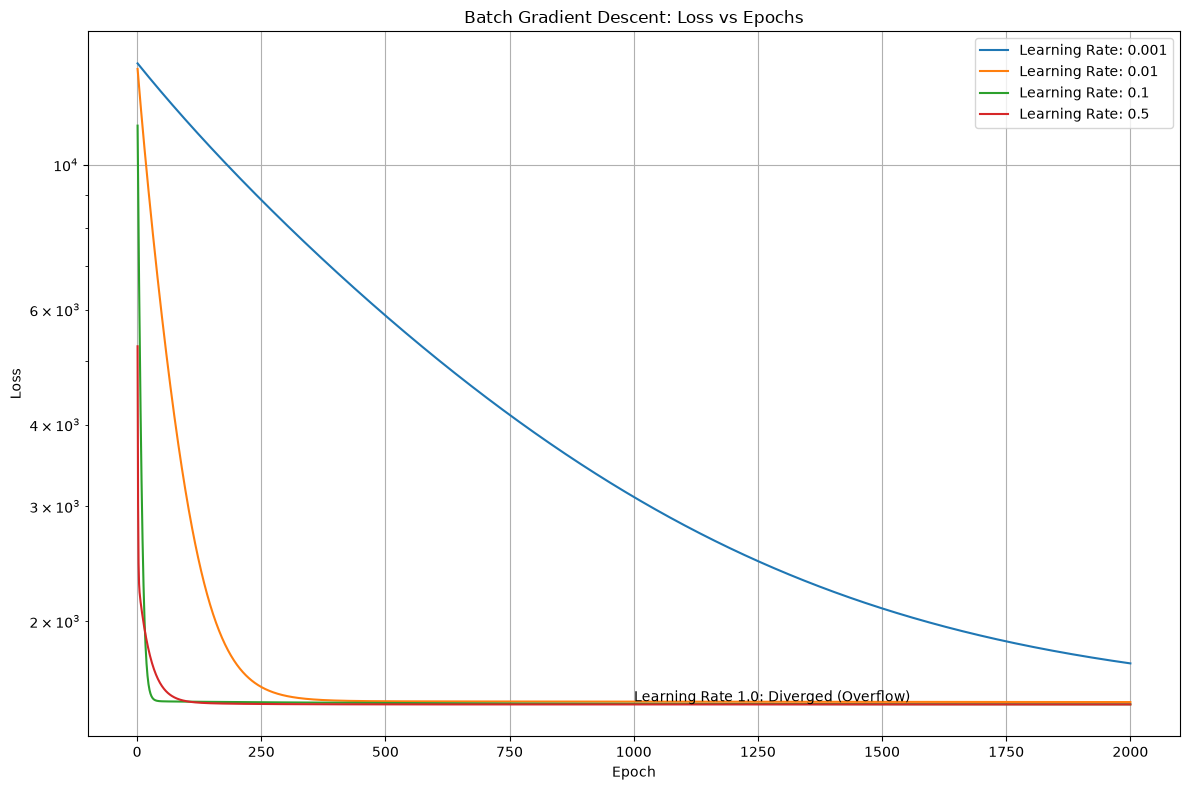

In [201]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

for lr in [0.001, 0.01, 0.1, 0.5]:
    losses = gd_results[lr]["losses"]

    epochs = np.arange(1, len(losses) + 1)

    valid = np.isfinite(losses) & (losses > 0)

    plt.plot(epochs[valid], losses[valid], label=f"Learning Rate: {lr}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.title("Batch Gradient Descent: Loss vs Epochs")

plt.text(0.5, 0.05, "Learning Rate 1.0: Diverged (Overflow)", transform=plt.gca().transAxes)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [202]:
results = []

for lr in learning_rates:
    losses = gd_results[lr]["losses"]
    distances = gd_results[lr]["distances"]

    reached = np.where(distances < 1e-3)[0]

    first_reached_epoch = (reached[0] + 1 if len(reached) > 0 else "not reached")

    results.append({
        "learning_rate": lr,
        "final_loss": losses[-1],
        "final_distance": distances[-1],
        "first_reached_epoch": first_reached_epoch
    })

results_df = pd.DataFrame(results)
display(results_df)

,learning_rate,final_loss,final_distance,first_reached_epoch
0,0.001,1723.402889,0.405113,not reached
1,0.010,1503.686676,0.334521,not reached
2,0.100,1491.892636,0.081792,not reached
3,0.500,1491.145907,0.000155,1524
4,1.000,NaN,NaN,not reached


In [203]:
#Compute λₘₐₓ, the largest eigenvalue of H = X̃ᵀX̃/N 

N = X_train_bias.shape[0]
H = (X_train_bias.T @ X_train_bias) / N

# calculate the largest eigenvalue of H
eigenvalue = np.linalg.eigvalsh(H)
lambda_max = np.max(eigenvalue)

# calculating critical rate
# eta(threshold) = 2/λₘₐₓ
#η = 0.95·(2/λₘₐₓ) converges and η = 1.05·(2/λₘₐₓ) diverges

eta = 2 / lambda_max
eta_converges = 0.95 * eta
eta_diverges = 1.05 * eta

print("Lambda max: ",lambda_max)
print("Threshold: ", eta)
print("converges: ",eta_converges)
print("diverges:", eta_diverges)

Lambda max:  3.954755032050376
Threshold:  0.5057203249737274
converges:  0.48043430872504106
diverges: 0.5310063412224139


In [204]:
w_converges, losses_converges, distances_converges = batch_gradient_descent(X_train_bias, y_train,
                                                                             W, learning_rate=eta_converges, epochs=2000)
w_diverges, losses_diverges, distances_diverges = batch_gradient_descent(X_train_bias, y_train,
                                                                          W, learning_rate=eta_diverges, epochs=2000)

print("Converges final distance:", distances_converges[-1])
print("Diverges final distance:", distances_diverges[-1])


Converges final distance: 0.00021023075314223705
Diverges final distance: 7.581863342433945e+81


In [205]:
# Task 7: Why scaling matters

#get the original, unstandardized Diabetes training features
X_train_raw = splits["Diabetes"]["X_train"]
y_train_raw = splits["Diabetes"]["y_train"]

#add the bias column
X_train_raw_bias = add_bias(X_train_raw)

#get the standardized training features from Task 5/6
X_train_standardized = prepared_datasets["Diabetes"]["X_train"]
X_train_standardized_bias = add_bias(X_train_standardized)

print("Raw features shape:", X_train_raw_bias.shape)
print("Standardized features shape:", X_train_standardized_bias.shape)

print("\nRaw feature standard deviations:")
print(np.std(X_train_raw, axis=0))

print("\nStandardized feature standard deviations:")
print(np.std(X_train_standardized, axis=0))

Raw features shape: (264, 11)
Standardized features shape: (264, 11)

Raw feature standard deviations:
[12.74507   0.499871  4.374058 14.007533 35.22319  31.242438 12.280194
  1.271273  0.501466 11.400465]

Standardized feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [206]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [207]:

# Task 7: Calculate condition number and learning rate limit

#calculate H = X^T X / N for raw features
N_raw = X_train_raw_bias.shape[0]
H_raw = (X_train_raw_bias.T @ X_train_raw_bias) / N_raw

#calculate H for standardized features
N_std = X_train_standardized_bias.shape[0]
H_std = (X_train_standardized_bias.T @ X_train_standardized_bias) / N_std

#condition numbers
cond_raw = np.linalg.cond(X_train_raw_bias.T @ X_train_raw_bias)
cond_std = np.linalg.cond(X_train_standardized_bias.T @ X_train_standardized_bias)

#largest eigenvalues
lambda_max_raw = np.linalg.eigvalsh(H_raw)[-1]
lambda_max_std = np.linalg.eigvalsh(H_std)[-1]

#maximum learning rate limits
eta_limit_raw = 2 / lambda_max_raw
eta_limit_std = 2 / lambda_max_std

#print results
print("Raw features:")
print("Condition number:", cond_raw)
print("2 / lambda_max:", eta_limit_raw)

print("\nStandardized features:")
print("Condition number:", cond_std)
print("2 / lambda_max:", eta_limit_std)


Raw features:
Condition number: 55778473.21647313
2 / lambda_max: 2.7427928748390996e-05

Standardized features:
Condition number: 505.706122696069
2 / lambda_max: 0.5057203249737274


c:\Users\Mega Store\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_15820\3539949200.py:5: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred) ** 2)
c:\Users\Mega Store\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\linalg\_linalg.py:2767: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_15820\1611338114.py:12: RuntimeWarning: overflow encountered in matmul
  gradient = (1 / N) * (X.T @ (predictions - y))
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_15820\1611338114.py:15: RuntimeWarning: invalid value encountered in subtract
  w -= learning_rate * gradient


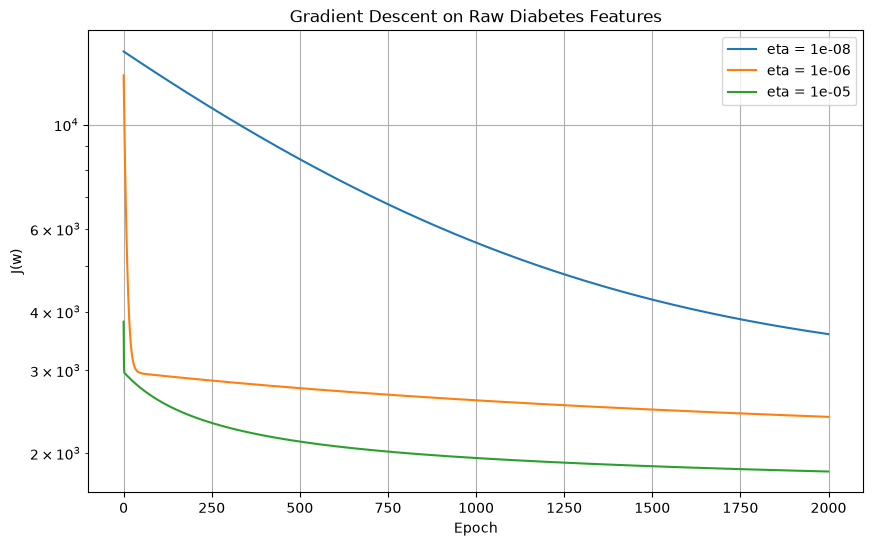

Learning Rate | Final J | Final Relative Distance | First Epoch < 1e-3
1e-08          | 3584       | 1                        | Not reached
1e-06          | 2389       | 1                        | Not reached
1e-05          | 1828       | 0.9998                   | Not reached
0.0001         | nan        | nan                      | Not reached


In [208]:

# Task 7: Gradient Descent on raw features

#calculate the optimal weights using raw features
w_star_raw = np.linalg.solve(
    X_train_raw_bias.T @ X_train_raw_bias,
    X_train_raw_bias.T @ y_train_raw
)

#learning rates required in task7
learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]

raw_results = {}

#run gradient descent for each learning rate
for eta in learning_rates:
    w, losses, distances = batch_gradient_descent(
        X_train_raw_bias,
        y_train_raw,
        w_star_raw,
        learning_rate=eta,
        epochs=2000
    )

    raw_results[eta] = {
        "weights": w,
        "losses": losses,
        "distances": distances
    }

#plot loss against epoch for stable learning rates only
plt.figure(figsize=(10, 6))

for eta in [1e-8, 1e-6, 1e-5]:
    plt.plot(
        raw_results[eta]["losses"],
        label=f"eta = {eta}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("J(w)")
plt.title("Gradient Descent on Raw Diabetes Features")
plt.legend()
plt.grid(True)
plt.show()

#print results table
print("Learning Rate | Final J | Final Relative Distance | First Epoch < 1e-3")

for eta in learning_rates:
    losses = raw_results[eta]["losses"]
    distances = raw_results[eta]["distances"]

    reached = np.where(distances < 1e-3)[0]

    first_epoch = reached[0] + 1 if len(reached) > 0 else "Not reached"

    print(
        f"{eta:<14} | "
        f"{losses[-1]:<10.4g} | "
        f"{distances[-1]:<24.4g} | "
        f"{first_epoch}"
    )
    


<--with the help of AI-->

The condition number is much higher for raw features (about 55.8 million) than standardized features (about 506). This means that raw features need a much smaller learning rate to keep gradient descent stable. Because of the small learning rates, gradient descent is very slow and does not reach the optimal solution within 2000 epochs. Standardization makes gradient descent faster, while η = 1e-4 causes divergence on raw features.

### PART B.3: Stochastic and Mini-Batch Gradient Descent

In [209]:

def mini_batch_gradient_descent(X, y, learning_rate=0.01,
                                epochs=100, batch_size=16):

    N = X.shape[0]
    w = np.zeros(X.shape[1]) #kol weight ykon b zero at beg

    losses = []
    updates = []

    update_count = 0

    rng = np.random.default_rng(42)

    for epoch in range(epochs):

        # Shuffle training data every epoch
        indices = rng.permutation(N)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Divide data into mini-batches
        for start in range(0, N, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            B = len(y_batch)

            # Calculate predictions
            predictions = X_batch @ w

            # Calculate gradient
            gradient = (X_batch.T @ (predictions - y_batch)) / B

            # Update weights
            w -= learning_rate * gradient

            update_count += 1

        # Calculate loss using training set
        full_predictions = X @ w

        loss = 0.5 * mean_squared_error(y, full_predictions)

        losses.append(loss)
        updates.append(update_count)

    return w, np.array(losses), np.array(updates)


#### Compare Different Batch Sizes

In [210]:

batch_sizes = [1, 16, 64, len(y_train)]

batch_results = {}

for B in batch_sizes:

    w, losses, updates = mini_batch_gradient_descent(
        X_train_bias,
        y_train,
        learning_rate=0.01,
        epochs=100,
        batch_size=B
    )

    batch_results[B] = {
        "weights": w,
        "losses": losses,
        "updates": updates
    }

    print("Batch size:", B)
    print("Final loss:", losses[-1])
    print("Total updates:", updates[-1])
    print("-" * 40)


Batch size: 1
Final loss: 1534.8083853086
Total updates: 26400
----------------------------------------
Batch size: 16
Final loss: 1505.665099007747
Total updates: 1700
----------------------------------------
Batch size: 64
Final loss: 1511.3753357143576
Total updates: 500
----------------------------------------
Batch size: 264
Final loss: 3085.440478999073
Total updates: 100
----------------------------------------


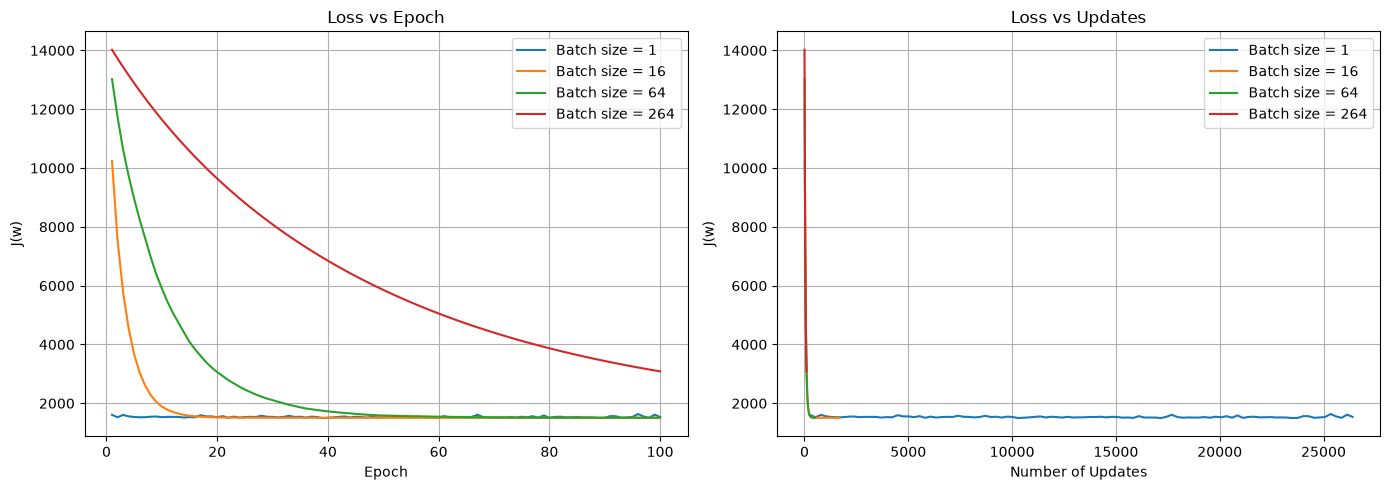

In [211]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for B in batch_sizes:

    losses = batch_results[B]["losses"]
    updates = batch_results[B]["updates"]

    axes[0].plot(
        np.arange(1, 101),
        losses,
        label=f"Batch size = {B}"
    )

    axes[1].plot(
        updates,
        losses,
        label=f"Batch size = {B}"
    )

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("J(w)")
axes[0].set_title("Loss vs Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Number of Updates")
axes[1].set_ylabel("J(w)")
axes[1].set_title("Loss vs Updates")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## SGD with different learning rates

In [212]:


learning_rates = [0.001, 0.01, 0.1]

sgd_results = {}

for eta in learning_rates:

    w, losses, updates = mini_batch_gradient_descent(
        X_train_bias,
        y_train,
        learning_rate=eta,
        epochs=100,
        batch_size=1
    )

    sgd_results[eta] = losses

    print(f"Learning Rate: {eta}")
    print(f"Final Loss: {losses[-1]}")
    print("-" * 30)


Learning Rate: 0.001
Final Loss: 1503.3121768105561
------------------------------
Learning Rate: 0.01
Final Loss: 1534.8083853086
------------------------------
Learning Rate: 0.1
Final Loss: 4186.980951940034
------------------------------


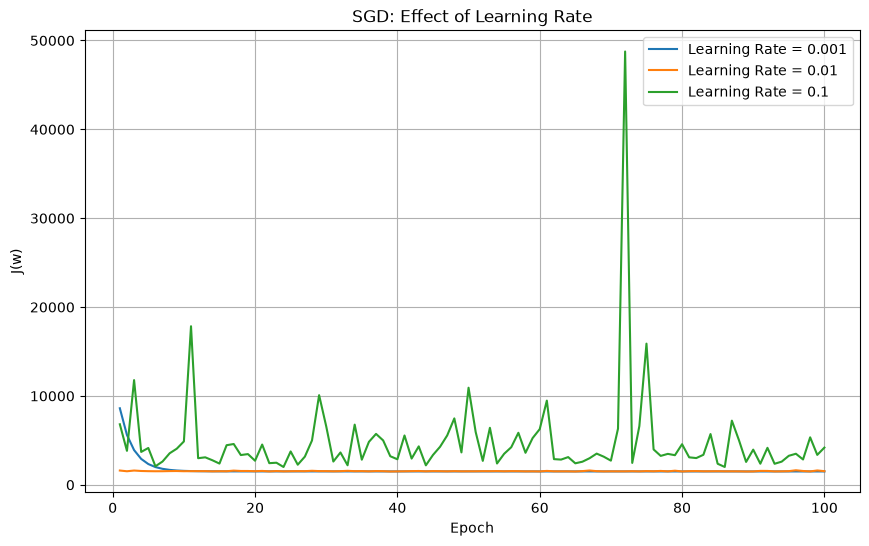

In [213]:

plt.figure(figsize=(10, 6))

for eta in learning_rates:

    plt.plot(
        range(1, 101),
        sgd_results[eta],
        label=f"Learning Rate = {eta}"
    )

plt.xlabel("Epoch")
plt.ylabel("J(w)")
plt.title("SGD: Effect of Learning Rate")
plt.legend()
plt.grid(True)
plt.show()


The batch size affects both the number of updates and the convergence behavior. Smaller batches perform more updates per epoch but produce noisier loss curves, while larger batches produce smoother updates but may require more epochs to converge. In our experiment, batch size 16 achieved the lowest final loss, while full-batch gradient descent converged more slowly.

For SGD, the learning rate strongly affects stability. Learning rates 0.001 and 0.01 produced relatively stable results, while 0.1 caused large fluctuations in the loss, indicating an excessively large learning rate.

### PART B.4 — Task 9: Ridge Regression (L2 Regularization)

Ridge Regression adds an L2 regularization term to the Linear Regression cost function to reduce overfitting and control large coefficients.

The objective function is:

\[
J_\lambda(w)=\frac{1}{2N}\|\tilde Xw-y\|^2+\frac{\lambda}{2}\|w_{1:}\|^2
\]

where:
- \(\lambda\) is the regularization parameter.
- \(w_0\) is the bias and is not penalized.
- \(w_{1:}\) represents all weights except the bias.

#### Ridge Regression: Small Worked Example

In [214]:

X_toy = np.array([[1.0],
                  [2.0],
                  [3.0]])

y_toy = np.array([2.0, 3.0, 5.0])

lam = 1.0

X_toy_bias = add_bias(X_toy)
N_toy = len(y_toy)

I0 = np.eye(X_toy_bias.shape[1])
I0[0, 0] = 0

w_toy = np.linalg.solve(
    (X_toy_bias.T @ X_toy_bias) / N_toy + lam * I0,
    (X_toy_bias.T @ y_toy) / N_toy
)

print("Ridge weights:", w_toy)

Ridge weights: [2.133333 0.6     ]


In [215]:
def ridge_closed_form(X, y, lam):
    X_b = add_bias(X)
    N = X_b.shape[0]

    I0 = np.eye(X_b.shape[1])
    I0[0, 0] = 0

    A = (X_b.T @ X_b) / N + lam * I0
    b = (X_b.T @ y) / N

    w = np.linalg.solve(A, b)

    return w

### Apply Ridge Regression on Diabetes original features

In [216]:
lambda_value = 0.1

w_ridge = ridge_closed_form(X_train, y_train, lambda_value)

print("Ridge weights:")
print(w_ridge)

print("Number of weights:", len(w_ridge))

Ridge weights:
[149.810606   1.715201 -10.272203  24.003127  14.036236  -6.722063
  -5.639887  -8.029795   7.876198  20.082479   4.826142]
Number of weights: 11


In [217]:
# Calculate Ridge predictions

X_train_bias = add_bias(X_train)
X_val_bias = add_bias(X_val)
X_test_bias = add_bias(X_test)

train_pred_ridge = X_train_bias @ w_ridge
val_pred_ridge = X_val_bias @ w_ridge
test_pred_ridge = X_test_bias @ w_ridge

# Calculate RMSE

train_rmse_ridge = root_mean_squared_error(y_train, train_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, val_pred_ridge)
test_rmse_ridge = root_mean_squared_error(y_test, test_pred_ridge)

print("Ridge Train RMSE:", train_rmse_ridge)
print("Ridge Validation RMSE:", val_rmse_ridge)
print("Ridge Test RMSE:", test_rmse_ridge)

Ridge Train RMSE: 54.98310683251263
Ridge Validation RMSE: 51.207304584010046
Ridge Test RMSE: 53.7089252748126


### Test different lambda values

In [218]:

lambdas = np.concatenate(([0.0], np.logspace(-3, 1, 9)))

ridge_results = {}

for lam in lambdas:
    w = ridge_closed_form(X_train, y_train, lam)

    val_pred = X_val_bias @ w
    test_pred = X_test_bias @ w

    ridge_results[lam] = {
        "weights": w,
        "val_rmse": root_mean_squared_error(y_val, val_pred),
        "test_rmse": root_mean_squared_error(y_test, test_pred)
    }

for lam, result in ridge_results.items():
    print(
        f"Lambda: {lam:.4f} | "
        f"Validation RMSE: {result['val_rmse']:.4f} | "
        f"Test RMSE: {result['test_rmse']:.4f}"
    )

Lambda: 0.0000 | Validation RMSE: 51.1937 | Test RMSE: 54.1564
Lambda: 0.0010 | Validation RMSE: 51.1496 | Test RMSE: 54.1082
Lambda: 0.0032 | Validation RMSE: 51.1080 | Test RMSE: 54.0437
Lambda: 0.0100 | Validation RMSE: 51.1047 | Test RMSE: 53.9585
Lambda: 0.0316 | Validation RMSE: 51.1531 | Test RMSE: 53.8600
Lambda: 0.1000 | Validation RMSE: 51.2073 | Test RMSE: 53.7089
Lambda: 0.3162 | Validation RMSE: 51.5780 | Test RMSE: 53.6724
Lambda: 1.0000 | Validation RMSE: 53.6951 | Test RMSE: 54.8569
Lambda: 3.1623 | Validation RMSE: 59.4203 | Test RMSE: 59.0928
Lambda: 10.0000 | Validation RMSE: 66.9546 | Test RMSE: 65.3039


### Plot Ridge coefficients vs Lambda

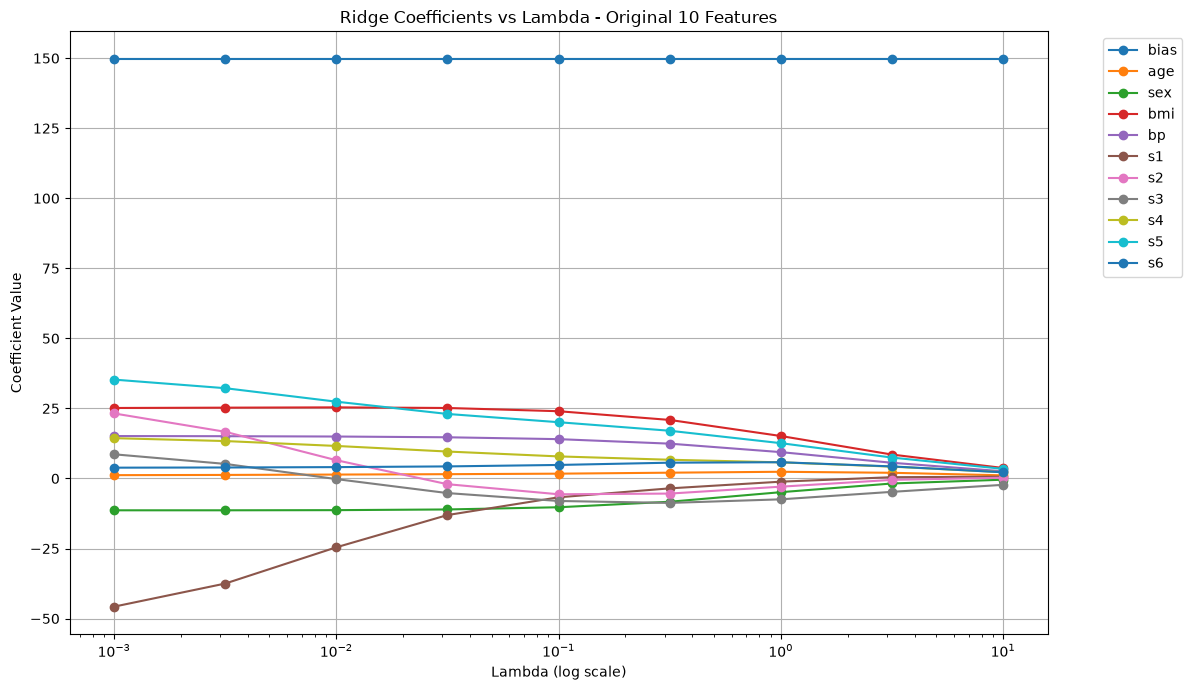

In [219]:
positive_lambdas = lambdas[lambdas > 0]

plt.figure(figsize=(12, 7))

for i, name in enumerate(feature_names):
    coefficients = [
        ridge_results[lam]["weights"][i]
        for lam in positive_lambdas
    ]

    plt.plot(positive_lambdas, coefficients, marker='o', label=name)

plt.xscale("log")
plt.xlabel("Lambda (log scale)")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients vs Lambda - Original 10 Features")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

### Plot Validation RMSE vs Lambda

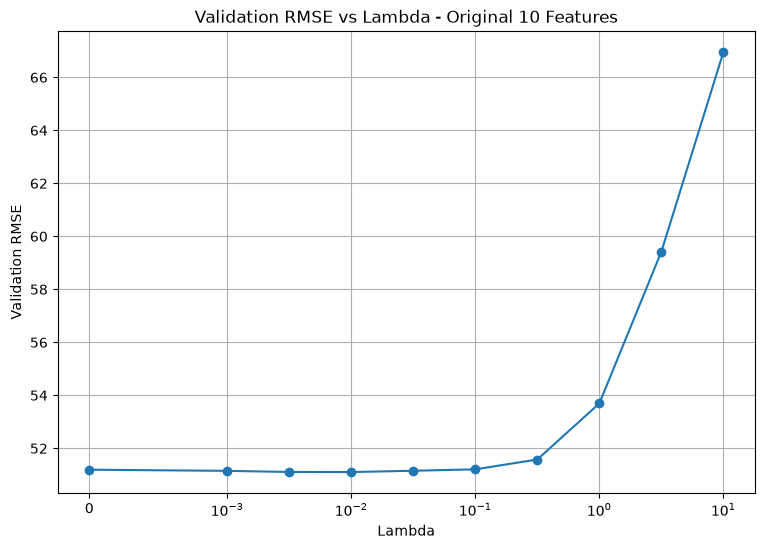

In [220]:
val_errors = [
    ridge_results[lam]["val_rmse"]
    for lam in lambdas
]

plt.figure(figsize=(9, 6))

plt.plot(lambdas, val_errors, marker='o')

plt.xscale("symlog", linthresh=0.001)
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE vs Lambda - Original 10 Features")
plt.grid(True)
plt.show()

In [221]:
def degree2_features(X):
    n, d = X.shape

    columns = [X[:, i] for i in range(d)]

    for i in range(d):
        for j in range(i, d):

            # Drop sex squared (feature index 1)
            if i == 1 and j == 1:
                continue

            columns.append(X[:, i] * X[:, j])

    return np.column_stack(columns)

In [222]:
X_train_poly = degree2_features(X_train)

print("Original features:", X_train.shape[1])
print("Degree-2 features:", X_train_poly.shape[1])

Original features: 10
Degree-2 features: 64


### Apply degree-2 expansion to all splits

In [223]:
X_train_poly = degree2_features(X_train)
X_val_poly = degree2_features(X_val)
X_test_poly = degree2_features(X_test)

# Standardize expanded features using training statistics

poly_scaler = Standardizer()

X_train_poly = poly_scaler.fit(X_train_poly).transform(X_train_poly)
X_val_poly = poly_scaler.transform(X_val_poly)
X_test_poly = poly_scaler.transform(X_test_poly)

print("Training shape:", X_train_poly.shape)
print("Validation shape:", X_val_poly.shape)
print("Testing shape:", X_test_poly.shape)

print("\nTraining means:", np.max(np.abs(np.mean(X_train_poly, axis=0))))
print("Training std difference from 1:",
      np.max(np.abs(np.std(X_train_poly, axis=0) - 1)))

Training shape: (264, 64)
Validation shape: (89, 64)
Testing shape: (89, 64)

Training means: 1.6811047503557058e-15
Training std difference from 1: 2.886579864025407e-15


### Calculate condition number for degree-2 features

In [224]:
X_train_poly_bias = add_bias(X_train_poly)

condition_poly = np.linalg.cond(
    X_train_poly_bias.T @ X_train_poly_bias
)

print("Condition number:", condition_poly)

Condition number: 38745023.49876948


### Ridge Regression on degree-2 features

In [225]:
X_train_poly_bias = add_bias(X_train_poly)
X_val_poly_bias = add_bias(X_val_poly)
X_test_poly_bias = add_bias(X_test_poly)

ridge_poly_results = {}

for lam in lambdas:
    w = ridge_closed_form(X_train_poly, y_train, lam)

    train_pred = X_train_poly_bias @ w
    val_pred = X_val_poly_bias @ w
    test_pred = X_test_poly_bias @ w

    ridge_poly_results[lam] = {
        "weights": w,
        "train_rmse": root_mean_squared_error(y_train, train_pred),
        "val_rmse": root_mean_squared_error(y_val, val_pred),
        "test_rmse": root_mean_squared_error(y_test, test_pred)
    }

for lam, result in ridge_poly_results.items():
    print(
        f"Lambda: {lam:.4f} | "
        f"Validation RMSE: {result['val_rmse']:.4f} | "
        f"Test RMSE: {result['test_rmse']:.4f}"
    )

Lambda: 0.0000 | Validation RMSE: 59.2059 | Test RMSE: 62.1334
Lambda: 0.0010 | Validation RMSE: 57.5162 | Test RMSE: 59.6321
Lambda: 0.0032 | Validation RMSE: 56.4321 | Test RMSE: 57.8254
Lambda: 0.0100 | Validation RMSE: 55.9068 | Test RMSE: 55.9476
Lambda: 0.0316 | Validation RMSE: 55.5088 | Test RMSE: 54.1278
Lambda: 0.1000 | Validation RMSE: 54.5155 | Test RMSE: 52.5914
Lambda: 0.3162 | Validation RMSE: 53.6917 | Test RMSE: 52.2647
Lambda: 1.0000 | Validation RMSE: 55.0007 | Test RMSE: 54.4479
Lambda: 3.1623 | Validation RMSE: 59.7101 | Test RMSE: 59.4956
Lambda: 10.0000 | Validation RMSE: 66.6136 | Test RMSE: 65.6472


### Create names for degree-2 features

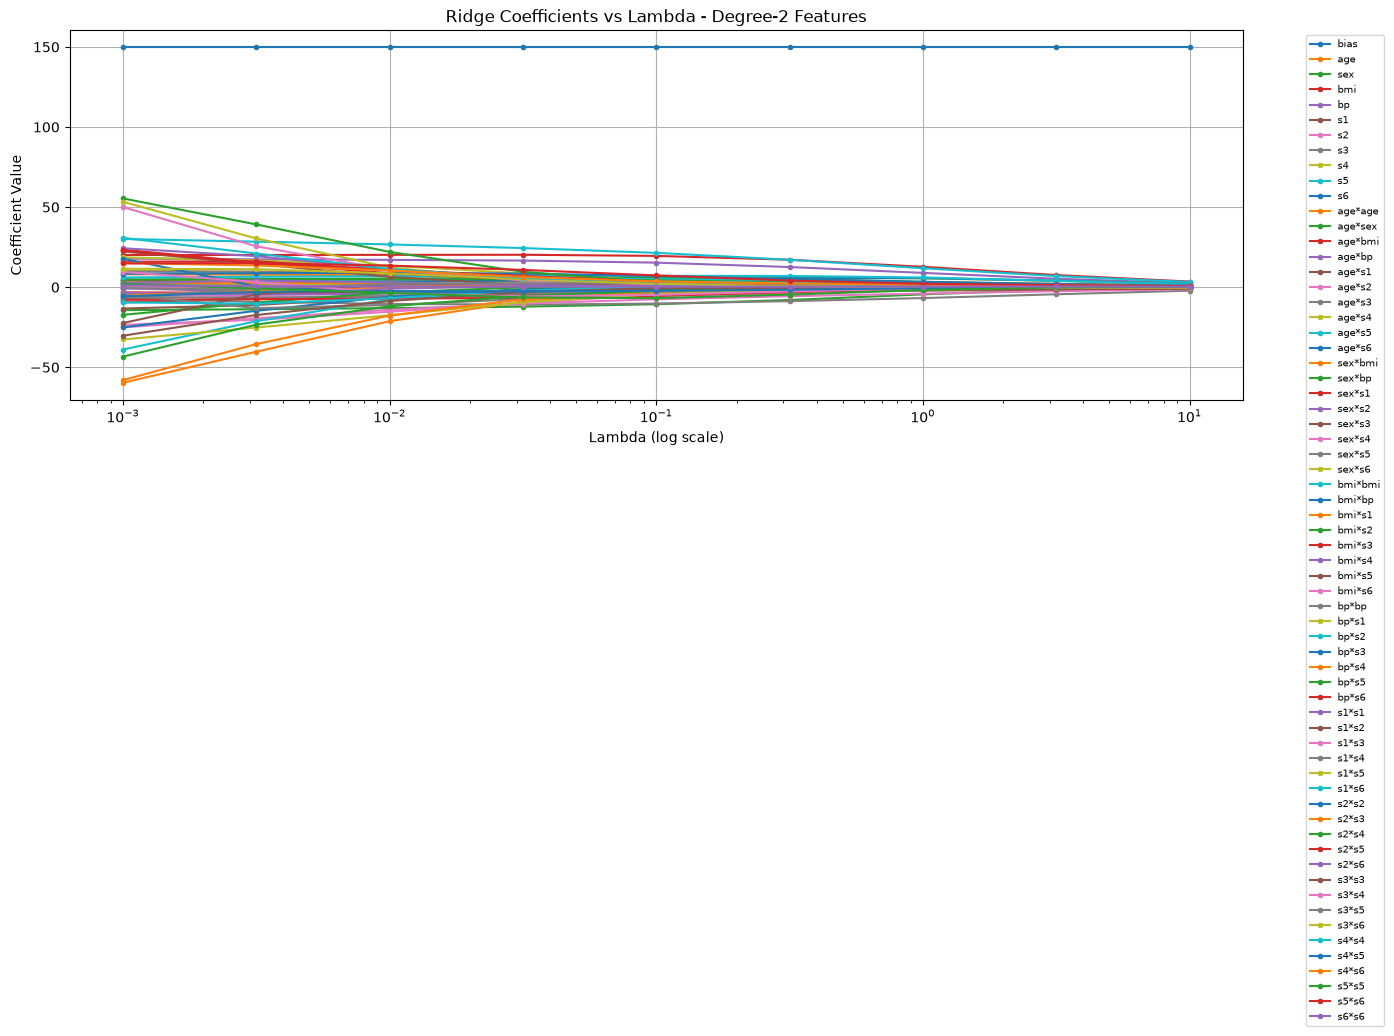

In [226]:
base_names = list(datasets["Diabetes"]["feature_names"])

poly_names = base_names.copy()

for i in range(len(base_names)):
    for j in range(i, len(base_names)):

        if i == 1 and j == 1:
            continue

        poly_names.append(f"{base_names[i]}*{base_names[j]}")

feature_names_poly = ["bias"] + poly_names

# Plot coefficients vs lambda

positive_lambdas = lambdas[lambdas > 0]

plt.figure(figsize=(14, 8))

for i, name in enumerate(feature_names_poly):
    coefficients = [
        ridge_poly_results[lam]["weights"][i]
        for lam in positive_lambdas
    ]

    plt.plot(positive_lambdas, coefficients, marker='o',
             markersize=3, label=name)

plt.xscale("log")
plt.xlabel("Lambda (log scale)")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients vs Lambda - Degree-2 Features")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=7)
plt.grid(True)
plt.tight_layout()
plt.show()

### Plot Validation RMSE vs Lambda for degree-2 features

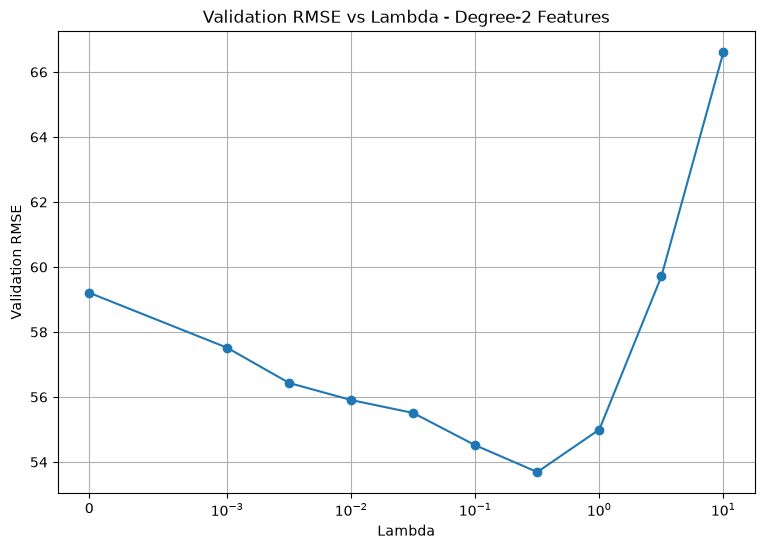

In [227]:
poly_val_errors = [
    ridge_poly_results[lam]["val_rmse"]
    for lam in lambdas
]

plt.figure(figsize=(9, 6))

plt.plot(lambdas, poly_val_errors, marker='o')

plt.xscale("symlog", linthresh=0.001)
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE vs Lambda - Degree-2 Features")
plt.grid(True)
plt.show()

### Select best lambda using validation RMSE


In [228]:
best_lambda_poly = min(
    ridge_poly_results,
    key=lambda lam: ridge_poly_results[lam]["val_rmse"]
)

best_result = ridge_poly_results[best_lambda_poly]

test_rmse_lambda0 = ridge_poly_results[0.0]["test_rmse"]
test_rmse_best = best_result["test_rmse"]

print("Best Lambda:", best_lambda_poly)
print("Best Validation RMSE:", best_result["val_rmse"])
print("Test RMSE at best lambda:", test_rmse_best)
print("Test RMSE at lambda = 0:", test_rmse_lambda0)

Best Lambda: 0.31622776601683794
Best Validation RMSE: 53.69171445031375
Test RMSE at best lambda: 52.264723336991295
Test RMSE at lambda = 0: 62.133373395428386


### Ridge Batch Gradient Descent


In [229]:
def ridge_batch_gd(X, y, lam, learning_rate=0.4, epochs=3000):

    X_b = add_bias(X)
    N = len(y)

    w = np.zeros(X_b.shape[1])

    I0 = np.eye(X_b.shape[1])
    I0[0, 0] = 0

    for epoch in range(epochs):

        predictions = X_b @ w

        gradient = (
            X_b.T @ (predictions - y) / N
            + lam * (I0 @ w)
        )

        w -= learning_rate * gradient

    return w


# Compare Batch GD with closed-form Ridge

lam = 0.1

w_closed = ridge_closed_form(X_train, y_train, lam)

w_gd = ridge_batch_gd(
    X_train, y_train,
    lam,
    learning_rate=0.4,
    epochs=3000
)

relative_distance = (
    np.linalg.norm(w_gd - w_closed)
    / np.linalg.norm(w_closed)
)

print("Relative distance:", relative_distance)

assert relative_distance < 1e-6

print("Batch GD verification passed!")

Relative distance: 5.814253687687576e-16
Batch GD verification passed!


In [230]:
from sklearn.linear_model import Ridge

lam = 0.1
N_train = len(y_train)

sk_ridge = Ridge(alpha=lam * N_train)
sk_ridge.fit(X_train, y_train)

sk_weights = np.concatenate((
    [sk_ridge.intercept_],
    sk_ridge.coef_
))

w_closed = ridge_closed_form(X_train, y_train, lam)

print("Maximum weight difference:",
      np.max(np.abs(w_closed - sk_weights)))

assert np.allclose(w_closed, sk_weights, atol=1e-6, rtol=0)

print("Sklearn Ridge verification passed!")

Maximum weight difference: 1.5631940186722204e-13
Sklearn Ridge verification passed!


For the original 10 features, Ridge provides only a small improvement because the number of features is relatively small compared with the number of training samples (264). After degree-2 expansion, the number of features increases to 64 while the number of training samples stays the same, increasing the risk of overfitting and making regularization more beneficial. Ridge reduces the magnitude of the coefficients, which helps control overfitting and improves generalization. The bias must not be penalized because it represents the baseline prediction, and penalizing it would unnecessarily push the intercept toward zero.

In [231]:
import time
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor

# Prepare data
X_train_bias = add_bias(X_train)
X_test_bias = add_bias(X_test)

N_train = len(y_train)

#helper functions
def calculate_rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def relative_distance(w, w_star):
    return np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

results = []

def save_result(name, w, fit_time):
    predictions = X_test_bias @ w

    results.append({
        "Method": name,
        "Test RMSE": calculate_rmse(y_test, predictions),
        "Relative Distance": relative_distance(w, w_star),
        "Fit Time (seconds)": fit_time
    })

#1-normal eqn
start = time.perf_counter()

w_star = np.linalg.solve(
    X_train_bias.T @ X_train_bias,
    X_train_bias.T @ y_train
)

normal_time = time.perf_counter() - start
save_result("Normal Equation", w_star, normal_time)

# 2-Batch Gradient Descent
start = time.perf_counter()

w_batch = np.zeros(X_train_bias.shape[1])

for epoch in range(2000):
    predictions = X_train_bias @ w_batch
    gradient = X_train_bias.T @ (predictions - y_train) / N_train
    w_batch -= 0.5 * gradient

batch_time = time.perf_counter() - start
save_result("Batch GD", w_batch, batch_time)

# 3-Mini-Batch GD
start = time.perf_counter()

w_mini, _, _ = mini_batch_gradient_descent(
    X_train_bias,
    y_train,
    learning_rate=0.01,
    epochs=100,
    batch_size=16
)

mini_time = time.perf_counter() - start
save_result("Mini-Batch GD (B=16)", w_mini, mini_time)

# 4-Ridge from scratch
start = time.perf_counter()

w_ridge = ridge_closed_form(X_train, y_train, 0.1)

ridge_time = time.perf_counter() - start
save_result("Ridge from scratch", w_ridge, ridge_time)

# 5-Scikit-learn Linear Regression
start = time.perf_counter()

sk_linear = LinearRegression()
sk_linear.fit(X_train, y_train)

linear_time = time.perf_counter() - start

w_linear = np.concatenate(([sk_linear.intercept_], sk_linear.coef_))
save_result("Sklearn LinearRegression", w_linear, linear_time)

# 6-Scikit-learn Ridge
start = time.perf_counter()

sk_ridge = Ridge(alpha=0.1 * N_train)
sk_ridge.fit(X_train, y_train)

sk_ridge_time = time.perf_counter() - start

w_sk_ridge = np.concatenate(([sk_ridge.intercept_], sk_ridge.coef_))
save_result("Sklearn Ridge", w_sk_ridge, sk_ridge_time)

# 7-Scikit-learn SGDRegressor
for eta in [0.001, 0.01, 0.1]:

    start = time.perf_counter()

    sk_sgd = SGDRegressor(
        penalty=None,
        learning_rate="constant",
        eta0=eta,
        max_iter=1000,
        tol=None,
        random_state=42
    )

    sk_sgd.fit(X_train, y_train)

    sgd_time = time.perf_counter() - start

    w_sgd = np.concatenate(([sk_sgd.intercept_[0]], sk_sgd.coef_))
    save_result(f"SGDRegressor (eta={eta})", w_sgd, sgd_time)

#show comparison table
comparison_df = pd.DataFrame(results)
display(comparison_df)


,Method,Test RMSE,Relative Distance,Fit Time (seconds)
0,Normal Equation,54.156413,0.000000e+00,0.000192
1,Batch GD,54.156254,1.546262e-04,0.046332
2,Mini-Batch GD (B=16),53.895449,3.421471e-01,0.016540
3,Ridge from scratch,53.708925,3.636136e-01,0.000153
4,Sklearn LinearRegression,54.156413,5.956974e-15,0.000876
5,Sklearn Ridge,53.708925,3.636136e-01,0.000765
6,SGDRegressor (eta=0.001),54.088486,4.976050e-02,0.010032
7,SGDRegressor (eta=0.01),54.898061,5.031993e-02,0.010432
8,SGDRegressor (eta=0.1),71.449348,3.949685e-01,0.010672


The Normal Equation and Scikit-learn LinearRegression produce almost identical results, while the Ridge implementation from scratch and Scikit-learn Ridge also agree closely. Gradient Descent gives a result very close to the optimal solution, whereas Mini-batch Gradient Descent and SGDRegressor show some differences because they use iterative updates and may not fully converge to the same weights. The SGDRegressor with a learning rate of 0.1 performs significantly worse than with 0.001 because the larger learning rate causes unstable updates.

# Part C — Logistic regression

In [232]:
cancer_split = prepared_datasets["Breast Cancer"]

X_train_c = cancer_split["X_train"]
X_val_c = cancer_split["X_val"]
X_test_c = cancer_split["X_test"]

y_train_c = cancer_split["y_train"]
y_val_c = cancer_split["y_val"]
y_test_c = cancer_split["y_test"]

print("Training:", X_train_c.shape)
print("Validation:", X_val_c.shape)
print("Testing:", X_test_c.shape)

print("Classes:", np.unique(y_train_c))

Training: (341, 30)
Validation: (114, 30)
Testing: (114, 30)
Classes: [0 1]


### PART C.1:Derivation and stable implementation
The predicted probability is:

[
p=\sigma(z), \qquad z=\tilde Xw
]

where the sigmoid function is:

[
\sigma(z)=\frac{1}{1+e^{-z}}
]

The Binary Cross-Entropy loss for one sample is:

[
\ell=-y\log(p)-(1-y)\log(1-p)
]

2. Gradient Derivation

Using the chain rule:

[
\frac{dp}{dz}=p(1-p)
]

\left(-\frac{y}{p}+\frac{1-y}{1-p}\right)p(1-p)
]

After simplification:

[
\frac{\partial \ell}{\partial z}=p-y
]

Therefore, the gradient for all samples is:

[
\nabla J(w)=\frac{1}{N}\tilde X^T(p-y)
]

With L2 regularization:

[
\nabla J(w)=\frac{1}{N}\tilde X^T(p-y)+\lambda[0,w_{1:}]
]

The bias term is not regularized.

3. Stable Loss Function

The loss can also be written as:

[
\ell(z,y)=\log(1+e^z)-yz
]

We use np.logaddexp(0,z) to calculate it safely and avoid numerical overflow.


In [233]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)

    result = np.empty_like(z)

    positive = z >= 0
    negative = ~positive

    result[positive] = 1 / (1 + np.exp(-z[positive]))

    exp_z = np.exp(z[negative])
    result[negative] = exp_z / (1 + exp_z)

    return result


print(sigmoid(np.array([-10, 0, 10])))

[0.000045 0.5      0.999955]


In [234]:
def logistic_loss(X, y, w, lam=0.0):
    X_b = add_bias(X)
    z = X_b @ w

    data_loss = np.mean(np.logaddexp(0, z) - y * z)

    reg_loss = (lam / 2) * np.sum(w[1:] ** 2)

    return data_loss + reg_loss

In [235]:
def logistic_gradient(X, y, w, lam=0.0):
    X_b = add_bias(X)
    N = len(y)

    p = sigmoid(X_b @ w)

    reg = np.zeros_like(w)
    reg[1:] = lam * w[1:]

    return X_b.T @ (p - y) / N + reg

In [236]:
z_extreme = np.array([-800.0, 800.0])
y_extreme = np.array([0.0, 1.0])

with np.errstate(over='ignore', divide='ignore', invalid='ignore'):
    p_naive = 1 / (1 + np.exp(-z_extreme))

    naive_loss = -np.mean(
        y_extreme * np.log(p_naive)
        + (1-y_extreme) * np.log(1-p_naive)
    )

stable_p = sigmoid(z_extreme)

stable_loss = np.mean(
    np.logaddexp(0, z_extreme) - y_extreme * z_extreme
)

print("Naive probabilities:", p_naive)
print("Naive loss:", naive_loss)
print("Stable probabilities:", stable_p)
print("Stable loss:", stable_loss)

Naive probabilities: [0. 1.]
Naive loss: nan
Stable probabilities: [0. 1.]
Stable loss: 0.0


In [237]:
# Gradient check for logistic regression with regularization
rng = np.random.default_rng(42)

X_small = rng.normal(size=(5, 3))
y_small = np.array([0, 1, 0, 1, 1])
w_small = rng.normal(size=4)

lam = 0.1

def loss_check(w):
    return logistic_loss(X_small, y_small, w, lam)

def gradient_check(w):
    return logistic_gradient(X_small, y_small, w, lam)

error = grad_check(loss_check, gradient_check, w_small)

print("Gradient check error:", error)

assert error < 1e-6

Gradient check error: 3.476467873382304e-11


### PART C.2:Training and regularization

In [238]:

def logistic_gradient_descent(
    X, y, X_val, y_val,
    learning_rate=0.5,
    epochs=3000,
    lam=0.0
):
    X_b = add_bias(X)
    X_val_b = add_bias(X_val)

    w = np.zeros(X_b.shape[1])

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # Update weights
        gradient = logistic_gradient(X, y, w, lam)
        w -= learning_rate * gradient

        # Training metrics
        train_losses.append(logistic_loss(X, y, w, lam))

        p_train = sigmoid(X_b @ w)
        train_pred = (p_train >= 0.5).astype(int)
        train_accuracies.append(accuracy_score(y, train_pred))

        # Validation metrics
        val_losses.append(logistic_loss(X_val, y_val, w, lam))

        p_val = sigmoid(X_val_b @ w)
        val_pred = (p_val >= 0.5).astype(int)
        val_accuracies.append(accuracy_score(y_val, val_pred))

    return w, train_losses, val_losses, train_accuracies, val_accuracies


Training for different lambda values

In [239]:

lambdas = [0, 1e-3, 1e-2, 1e-1, 1]

results = {}

for lam in lambdas:

    w, train_loss, val_loss, train_acc, val_acc = logistic_gradient_descent(
        X_train_c, y_train_c,
        X_val_c, y_val_c,
        learning_rate=0.5,
        epochs=3000,
        lam=lam
    )

    results[lam] = {
        "weights": w,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc
    }

print("Training completed for all lambda values.")


Training completed for all lambda values.


In [240]:

rows = []

for lam in lambdas:
    r = results[lam]
    w = r["weights"]

    rows.append({
        "Lambda": lam,
        "Train Accuracy": r["train_acc"][-1],
        "Validation Accuracy": r["val_acc"][-1],
        "Validation Loss": r["val_loss"][-1],
        "Weight Norm": np.linalg.norm(w[1:])
    })

results_table = pd.DataFrame(rows)
display(results_table)


,Lambda,Train Accuracy,Validation Accuracy,Validation Loss,Weight Norm
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.086207,5.099928
2,0.010,0.985337,0.973684,0.110010,2.325749
3,0.100,0.973607,0.973684,0.202665,1.105547
4,1.000,0.938416,0.956140,0.389668,0.441485


Best lambda + Test Accuracy

In [241]:
best_lam = min(lambdas, key=lambda lam: results[lam]["val_loss"][-1])

best = results[best_lam]
w_best = best["weights"]

p_test = sigmoid(add_bias(X_test_c) @ w_best)
test_pred = (p_test >= 0.5).astype(int)

print("Best Lambda:", best_lam)
print("Test Accuracy:", accuracy_score(y_test_c, test_pred))

Best Lambda: 0
Test Accuracy: 0.9736842105263158


Plot Training and Validation Loss & Accuracy

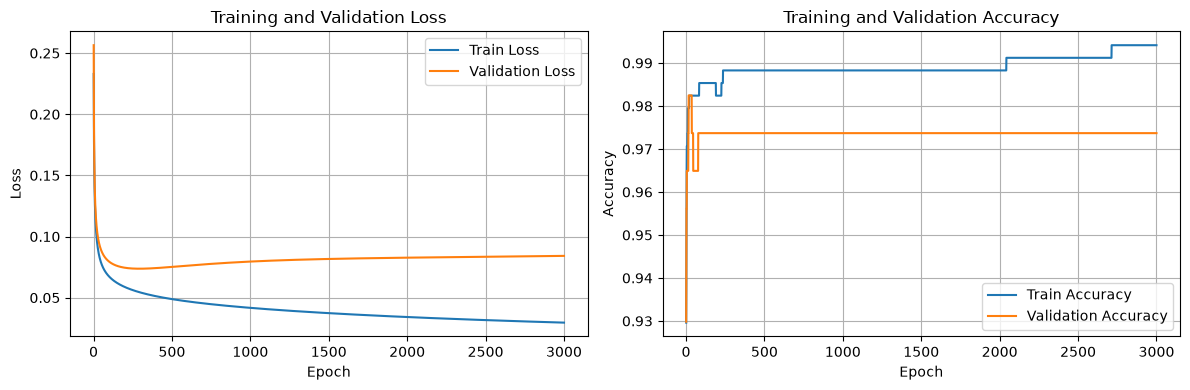

In [242]:
import matplotlib.pyplot as plt

epochs_axis = np.arange(1, 3001)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(epochs_axis, best["train_loss"], label="Train Loss")
axes[0].plot(epochs_axis, best["val_loss"], label="Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epochs_axis, best["train_acc"], label="Train Accuracy")
axes[1].plot(epochs_axis, best["val_acc"], label="Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Learning Rate Experiment

In [243]:
learning_rates = [0.01, 0.1, 1, 5, 20]

lr_results = []

for eta in learning_rates:

    w, train_loss, val_loss, train_acc, val_acc = logistic_gradient_descent(
        X_train_c, y_train_c,
        X_val_c, y_val_c,
        learning_rate=eta,
        epochs=1000,
        lam=0.01
    )

    lr_results.append({
        "Learning Rate": eta,
        "Final Train Loss": train_loss[-1]
    })

lr_table = pd.DataFrame(lr_results)

display(lr_table)

,Learning Rate,Final Train Loss
0,0.01,0.116289
1,0.10,0.098311
2,1.00,0.098112
3,5.00,0.098112
4,20.00,0.115389


### Observations

- The best regularization parameter was \(\lambda=0\), as it achieved the lowest validation loss.
- Increasing lambda reduced the weight norm and training accuracy.
- The training loss decreased continuously, while the validation loss started increasing slightly after reaching its minimum, indicating mild overfitting.
- A learning rate of 0.01 was too small and resulted in slower convergence.
- Learning rates of 0.1, 1, and 5 achieved lower final training losses, while a learning rate of 20 produced a worse result, indicating unstable training.

### PART C.3: Separability

In [244]:
epochs = 20000
learning_rate = 0.5
lam = 0.0

X_b = add_bias(X_train_c)

w_sep = np.zeros(X_b.shape[1])

weight_norms = []
training_losses = []

for epoch in range(epochs):

    gradient = logistic_gradient(
        X_train_c, y_train_c, w_sep, lam
    )

    w_sep -= learning_rate * gradient

    # Weight norm (excluding bias)
    weight_norms.append(np.linalg.norm(w_sep[1:]))

    # Training loss
    training_losses.append(
        logistic_loss(X_train_c, y_train_c, w_sep, lam)
    )

print("Final Weight Norm:", weight_norms[-1])
print("Final Training Loss:", training_losses[-1])

Final Weight Norm: 19.079104091096845
Final Training Loss: 0.011458238949846761


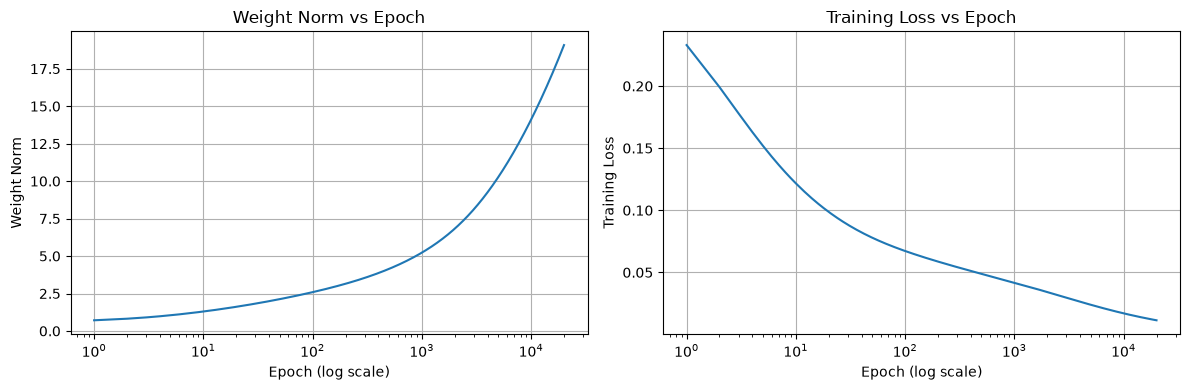

In [245]:
#plot the results
epochs_axis = np.arange(1, epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Weight Norm
axes[0].plot(epochs_axis, weight_norms)
axes[0].set_xscale("log")
axes[0].set_xlabel("Epoch (log scale)")
axes[0].set_ylabel("Weight Norm")
axes[0].set_title("Weight Norm vs Epoch")
axes[0].grid(True)

# Training Loss
axes[1].plot(epochs_axis, training_losses)
axes[1].set_xscale("log")
axes[1].set_xlabel("Epoch (log scale)")
axes[1].set_ylabel("Training Loss")
axes[1].set_title("Training Loss vs Epoch")
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Separability

**Observations:**

- The weight norm keeps increasing as the number of epochs increases.
- The training loss keeps decreasing and approaches zero.
- These curves provide numerical evidence that the training data is linearly separable.

**Explanation:**

For linearly separable data, logistic regression can keep increasing the weights to make the predictions more confident and reduce the training loss.

The loss approaches zero as the weight norm increases, but it does not reach zero for any finite set of weights. Therefore, without regularization, there is no finite weight vector that minimizes the logistic loss.

L2 regularization solves this problem by penalizing large weights, preventing them from growing indefinitely and producing a finite solution.

### PART C.4: Off-the-shelf comparison

In [246]:
#Compare with sklearn

from sklearn.linear_model import LogisticRegression

sklearn_results = []

N_train = len(y_train_c)

for lam in lambdas:

    if lam == 0:
        C = np.inf
    else:
        C = 1 / (lam * N_train)

    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=100000,
        tol=1e-12
    )

    model.fit(X_train_c, y_train_c)

    train_pred = model.predict(X_train_c)
    val_pred = model.predict(X_val_c)
    test_pred = model.predict(X_test_c)

    sklearn_results.append({
        "Lambda": lam,
        "Train Accuracy": accuracy_score(y_train_c, train_pred),
        "Validation Accuracy": accuracy_score(y_val_c, val_pred),
        "Test Accuracy": accuracy_score(y_test_c, test_pred)
    })

sklearn_table = pd.DataFrame(sklearn_results)

display(sklearn_table)

,Lambda,Train Accuracy,Validation Accuracy,Test Accuracy
0,0.000,1.000000,0.964912,0.964912
1,0.001,0.988270,0.973684,0.973684
2,0.010,0.985337,0.973684,0.982456
3,0.100,0.973607,0.973684,0.973684
4,1.000,0.938416,0.956140,0.921053


In [247]:
#Compare weights with sklearn

lam_compare = 0.01

N_train = len(y_train_c)
C = 1 / (lam_compare * N_train)

# Train sklearn model
sk_model = LogisticRegression(
    C=C,
    solver="lbfgs",
    max_iter=100000,
    tol=1e-12
)

sk_model.fit(X_train_c, y_train_c)

# Our weights
w_custom = results[lam_compare]["weights"]

# sklearn weights (including bias)
w_sklearn = np.concatenate((
    sk_model.intercept_,
    sk_model.coef_[0]
))

# Relative error
relative_error = (
    np.linalg.norm(w_custom - w_sklearn)
    / np.linalg.norm(w_sklearn)
)

# Compare test predictions
custom_pred = (
    sigmoid(add_bias(X_test_c) @ w_custom) >= 0.5
).astype(int)

sklearn_pred = sk_model.predict(X_test_c)

predictions_match = np.array_equal(
    custom_pred, sklearn_pred
)

print("Relative Error:", relative_error)
print("Predictions Match:", predictions_match)

Relative Error: 5.389593008309424e-07
Predictions Match: True


In [248]:
#Compare the solvers  
import time

lam_compare = 0.01
C = 1 / (lam_compare * len(y_train_c))

solvers = ["lbfgs", "liblinear", "saga"]

solver_results = []

for solver in solvers:

    model = LogisticRegression(
        C=C,
        solver=solver,
        max_iter=100000,
        tol=1e-12,
        random_state=42
    )

    start = time.time()

    model.fit(X_train_c, y_train_c)

    elapsed_time = time.time() - start

    solver_results.append({
        "Solver": solver,
        "Iterations": model.n_iter_[0],
        "Training Time": elapsed_time,
        "Coefficient Norm": np.linalg.norm(model.coef_)
    })

solver_table = pd.DataFrame(solver_results)

display(solver_table)

,Solver,Iterations,Training Time,Coefficient Norm
0,lbfgs,29,0.011087,2.325749
1,liblinear,10,0.004529,2.347991
2,saga,1354,0.147829,2.325749


### Solver Comparison — Observations

- LBFGS converged in 29 iterations.
- LIBLINEAR required only 10 iterations and had the shortest training time in this experiment.
- SAGA required more iterations and had the longest training time.
- LBFGS and SAGA produced nearly identical coefficient norms.
- LIBLINEAR produced a slightly different coefficient norm because it also regularizes the intercept, unlike the other two solvers.

The difference in intercept regularization can lead to slightly different model coefficients and predictions.

In [249]:
# C sweep

C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

C_results = []

for C in C_values:

    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=100000
    )

    model.fit(X_train_c, y_train_c)

    C_results.append({
        "C": C,
        "Train Accuracy": accuracy_score(
            y_train_c, model.predict(X_train_c)
        ),
        "Validation Accuracy": accuracy_score(
            y_val_c, model.predict(X_val_c)
        ),
        "Test Accuracy": accuracy_score(
            y_test_c, model.predict(X_test_c)
        )
    })

C_table = pd.DataFrame(C_results)
display(C_table)

,C,Train Accuracy,Validation Accuracy,Test Accuracy
0,0.001,0.879765,0.903509,0.868421
1,0.010,0.950147,0.964912,0.947368
2,0.100,0.979472,0.982456,0.982456
3,1.000,0.988270,0.973684,0.973684
4,10.000,0.997067,0.964912,0.964912
5,100.000,1.000000,0.956140,0.956140
6,1000.000,1.000000,0.947368,0.956140


### C Sweep — Observations

- A small C value (0.001) causes strong regularization and underfitting.
- Increasing C improves training accuracy.
- At C = 0.1, the model achieves the highest validation accuracy of 98.25%.
- For C values of 100 and 1000, training accuracy reaches 100%, while validation accuracy decreases.
- This indicates overfitting when regularization becomes too weak.

In [250]:
# Compare intercepts between solvers

for solver in ["lbfgs", "liblinear", "saga"]:

    model = LogisticRegression(
        C=1 / (0.01 * len(y_train_c)),
        solver=solver,
        max_iter=100000,
        tol=1e-12,
        random_state=42
    )

    model.fit(X_train_c, y_train_c)

    print(solver, "Intercept:", model.intercept_[0])

lbfgs Intercept: -0.4238166853100683
liblinear Intercept: -0.28790000564117263
saga Intercept: -0.42381638596064053


**Observation:** The `lbfgs` and `saga` solvers produce almost identical intercepts, while `liblinear` produces a different value. This is because `liblinear` regularizes the intercept, whereas `lbfgs` and `saga` do not. Therefore, the choice of solver can slightly affect the learned parameters.

### PART C.5:Evaluation beyond accuracy 

In [251]:
#cal for Confusion Matrix, Precision, Recall, F1-score
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

lam_compare = 0.01
w_compare = results[lam_compare]["weights"]

# Predict probabilities
test_prob = sigmoid(add_bias(X_test_c) @ w_compare)

# Convert probabilities to 0 or 1
test_pred = (test_prob >= 0.5).astype(int)

# Calculate metrics
cm = confusion_matrix(y_test_c, test_pred)
precision = precision_score(y_test_c, test_pred)
recall = recall_score(y_test_c, test_pred)
f1 = f1_score(y_test_c, test_pred)

print("Confusion Matrix:\n", cm)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Confusion Matrix:
 [[72  0]
 [ 2 40]]
Precision: 1.0
Recall: 0.9523809523809523
F1-score: 0.975609756097561


**Observations (Threshold = 0.5):**

- The model correctly classified 72 benign cases and 40 malignant cases.
- It produced 0 false positives and 2 false negatives.
- Precision = 1.0, meaning all predicted malignant cases were actually malignant.
- Recall = 0.9524, meaning the model detected about 95.24% of malignant cases.
- F1-score = 0.9756, indicating a strong balance between precision and recall.

The model performs very well, but missing 2 malignant cases is important in a medical screening problem.

ROC Curve from scratch

In [252]:
val_prob = sigmoid(add_bias(X_val_c) @ w_compare)

print("Validation probabilities:", val_prob[:10])
print("Number of validation samples:", len(val_prob))
print("Number of malignant cases:", np.sum(y_val_c == 1))

Validation probabilities: [0.029601 1.       0.000017 0.032811 0.031547 0.033438 0.10863  1.
 0.99297  0.146025]
Number of validation samples: 114
Number of malignant cases: 43


TPR (Recall) = TP / (TP + FN)
FPR = FP / (FP + TN)

In [253]:
def roc_curve_scratch(y_true, scores):

    thresholds = np.sort(np.unique(scores))[::-1]

    thresholds = np.append(thresholds, 0)

    tpr_list = []
    fpr_list = []

    for threshold in thresholds:

        predictions = (scores >= threshold).astype(int)

        TP = np.sum((y_true == 1) & (predictions == 1))
        FN = np.sum((y_true == 1) & (predictions == 0))
        FP = np.sum((y_true == 0) & (predictions == 1))
        TN = np.sum((y_true == 0) & (predictions == 0))

        TPR = TP / (TP + FN)
        FPR = FP / (FP + TN)

        tpr_list.append(TPR)
        fpr_list.append(FPR)

    return np.array(fpr_list), np.array(tpr_list)


fpr, tpr = roc_curve_scratch(y_val_c, val_prob)

print("Number of ROC points:", len(fpr))
print("First 5 FPR values:", fpr[:5])
print("First 5 TPR values:", tpr[:5])

Number of ROC points: 115
First 5 FPR values: [0. 0. 0. 0. 0.]
First 5 TPR values: [0.023256 0.046512 0.069767 0.093023 0.116279]


AUC (from scratch): 0.9957418932197838


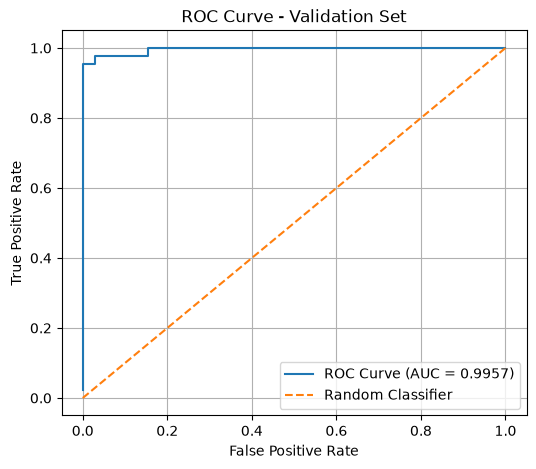

In [254]:
# Calculate AUC using trapezoidal rule
auc = np.trapezoid(tpr, fpr)

print("AUC (from scratch):", auc)

# Plot ROC curve
plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set")
plt.legend()
plt.grid()
plt.show()

In [255]:
from sklearn.metrics import roc_auc_score

# Add the starting point (0, 0)
fpr_corrected = np.insert(fpr, 0, 0)
tpr_corrected = np.insert(tpr, 0, 0)

# Calculate AUC from scratch
auc_scratch = np.trapezoid(tpr_corrected, fpr_corrected)

# Compare with sklearn
auc_sklearn = roc_auc_score(y_val_c, val_prob)

print("AUC from scratch:", auc_scratch)
print("AUC from sklearn:", auc_sklearn)
print("Absolute difference:", abs(auc_scratch - auc_sklearn))

assert abs(auc_scratch - auc_sklearn) < 1e-6

AUC from scratch: 0.9957418932197839
AUC from sklearn: 0.9957418932197838
Absolute difference: 1.1102230246251565e-16


**Observation:**

The AUC calculated from scratch is 0.9957, which is almost identical to the AUC calculated using sklearn.

The absolute difference is approximately \(1.11 \times 10^{-16}\), which is negligible.

This confirms that our ROC curve and AUC implementation are correct. The model has excellent discrimination ability on the validation set.

In [256]:
# Find the minimum probability among actual malignant cases
min_malignant_prob = np.min(val_prob[y_val_c == 1])

# Largest threshold that gives recall = 1
best_threshold = min_malignant_prob

val_pred_threshold = (val_prob >= best_threshold).astype(int)

threshold_recall = recall_score(y_val_c, val_pred_threshold)

print("Selected Threshold:", best_threshold)
print("Validation Recall:", threshold_recall)

Selected Threshold: 0.14602532493304418
Validation Recall: 1.0


In [257]:
# Predictions using the new threshold
test_pred_new = (test_prob >= best_threshold).astype(int)

# New threshold metrics
cm_new = confusion_matrix(y_test_c, test_pred_new)

precision_new = precision_score(y_test_c, test_pred_new)
recall_new = recall_score(y_test_c, test_pred_new)
f1_new = f1_score(y_test_c, test_pred_new)

print("Threshold:", best_threshold)
print("Confusion Matrix:\n", cm_new)
print("Precision:", precision_new)
print("Recall:", recall_new)
print("F1-score:", f1_new)

print("\nComparison with threshold = 0.5")
print("Old Recall:", recall_score(y_test_c, test_pred))
print("New Recall:", recall_new)

Threshold: 0.14602532493304418
Confusion Matrix:
 [[66  6]
 [ 1 41]]
Precision: 0.8723404255319149
Recall: 0.9761904761904762
F1-score: 0.9213483146067416

Comparison with threshold = 0.5
Old Recall: 0.9523809523809523
New Recall: 0.9761904761904762


**Screening Threshold Discussion:**

1. In medical screening, false negatives are particularly dangerous because a malignant case may be missed, delaying diagnosis and treatment.
2. False positives are also costly because they may cause unnecessary anxiety and additional medical tests.
3. The lower threshold of 0.146 increased recall on the test set from 95.24% to 97.62%, reducing false negatives from 2 to 1, but increased false positives from 0 to 6.
4. However, the selected threshold may not generalize reliably because it was tuned using only 43 malignant validation cases, so it should be validated on a larger independent dataset.

### PART C.6:The boundary in original coordinates

In [258]:
from sklearn.datasets import load_breast_cancer

cancer_data = load_breast_cancer()
feature_names = cancer_data.feature_names

radius_idx = np.where(feature_names == "mean radius")[0][0]
texture_idx = np.where(feature_names == "mean texture")[0][0]

X_train_2 = X_train_c[:, [radius_idx, texture_idx]]
X_val_2 = X_val_c[:, [radius_idx, texture_idx]]

w_2, train_loss_2, val_loss_2, train_acc_2, val_acc_2 = logistic_gradient_descent(
    X_train_2, y_train_c,
    X_val_2, y_val_c,
    learning_rate=0.5,
    epochs=5000,
    lam=0.0
)

print("Weights:", w_2)
print("Final Training Loss:", train_loss_2[-1])
print("Final Validation Loss:", val_loss_2[-1])
print("Final Training Accuracy:", train_acc_2[-1])
print("Final Validation Accuracy:", val_acc_2[-1])

Weights: [-0.727172  3.656794  1.009872]
Final Training Loss: 0.24683361156367858
Final Validation Loss: 0.28580887190987475
Final Training Accuracy: 0.9002932551319648
Final Validation Accuracy: 0.868421052631579


In [259]:
# Calculate mean and standard deviation using raw training data
y_original = 1 - cancer_data.target

recreated_split = split_dataset(
    cancer_data.data,
    y_original,
    task="classification"
)

X_train_2_raw = recreated_split["X_train"][:, [radius_idx, texture_idx]]

mu_2 = np.mean(X_train_2_raw, axis=0)
sigma_2 = np.std(X_train_2_raw, axis=0)

\[
w_j^{orig}=\frac{w_j}{\sigma_j}
\]

\[
w_0^{orig}=w_0-\sum_j\frac{w_j\mu_j}{\sigma_j}
\]

In [260]:
w_orig = np.zeros(3)

w_orig[1:] = w_2[1:] / sigma_2
w_orig[0] = w_2[0] - np.sum(w_2[1:] * mu_2 / sigma_2)

print("Original weights:", w_orig)

Original weights: [-19.643444   1.017461   0.231901]


In [261]:
#Verify the scores
scores_standardized = add_bias(X_train_2) @ w_2
scores_original = add_bias(X_train_2_raw) @ w_orig

max_difference = np.max(
    np.abs(scores_standardized - scores_original)
)

print("Maximum score difference:", max_difference)
print("Verification passed:", max_difference < 1e-9)

Maximum score difference: 9.769962616701378e-15
Verification passed: True


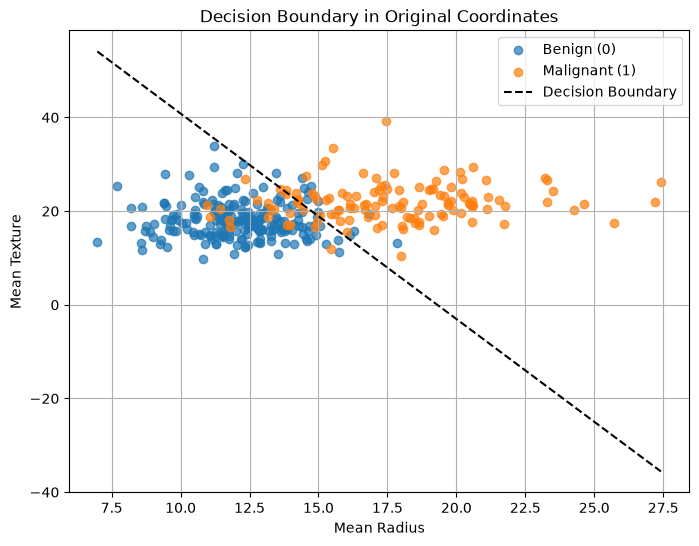

In [262]:
#Plot the decision boundary
import matplotlib.pyplot as plt

x = X_train_2_raw[:, 0]
y = X_train_2_raw[:, 1]

benign = y_train_c == 0
malignant = y_train_c == 1

plt.figure(figsize=(8, 6))

plt.scatter(x[benign], y[benign], label="Benign (0)", alpha=0.7)
plt.scatter(x[malignant], y[malignant], label="Malignant (1)", alpha=0.7)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = -(w_orig[0] + w_orig[1] * x_line) / w_orig[2]

plt.plot(x_line, y_line, "k--", label="Decision Boundary")

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Decision Boundary in Original Coordinates")
plt.legend()
plt.grid(True)
plt.show()

# Part D — Softmax classifier

### Task 17. Stable softmax and gradient.

In [263]:
def softmax(Z):
    Z = Z - Z.max(1, keepdims=True)
    e = np.exp(Z)
    return e / e.sum(1, keepdims=True)

In [264]:
def softmax_loss(W,X,y,lam=0):
    S=X@W
    logsum=np.logaddexp.reduce(S,axis=1)
    return np.mean(logsum-S[np.arange(len(y)),y])+lam/2*np.sum(W[1:]**2)

In [265]:
def softmax_grad(W,X,y,lam=0):
    P=softmax(X@W)
    P[np.arange(len(y)),y]-=1
    G=X.T@P/len(y)
    G[1:]+=lam*W[1:]
    return G

In [266]:
digits_split = prepared_datasets["Digits"]
X_train_digits = add_bias(digits_split["X_train"])
X_val_digits = add_bias(digits_split["X_val"])
X_test_digits = add_bias(digits_split["X_test"])
y_train_digits = digits_split["y_train"]
y_val_digits = digits_split["y_val"]
y_test_digits = digits_split["y_test"]

In [267]:
W0=np.zeros((X_train_digits.shape[1],10))
print("Loss at zero (expect ln(10)):",softmax_loss(W0,X_train_digits,y_train_digits))
print("Softmax example:",softmax(np.array([[1000.,1001.,1002.]])))
Wrand=rng.normal(0,.12,W0.shape)
print("Softmax gradient error:",grad_check(
    lambda v:softmax_loss(v.reshape(W0.shape),X_train_digits,y_train_digits,.1),
    lambda v:softmax_grad(v.reshape(W0.shape),X_train_digits,y_train_digits,.1).ravel(),
    Wrand.ravel(),num_checks=100,rng=rng))

Loss at zero (expect ln(10)): 2.3025850929940455
Softmax example: [[0.090031 0.244728 0.665241]]
Softmax gradient error: 7.903433156044874e-10


### Task 18. Training and model selection.

In [268]:
y_train = np.asarray(y_train, dtype=int).ravel()
y_val   = np.asarray(y_val, dtype=int).ravel()
y_test  = np.asarray(y_test, dtype=int).ravel()

In [269]:
def train_softmax_minibatch(X,y,Xv,yv,kind,eta,lam,epochs=100,B=64):
    local_rng=np.random.default_rng(42)
    W=np.zeros((X.shape[1],len(np.unique(y))))
    hist={"train_loss":[],"val_loss":[],"train_acc":[],"val_acc":[]}
    for _ in range(epochs):
        order=local_rng.permutation(len(y))
        for start in range(0,len(y),B):
            ix=order[start:start+B]
            if kind=="softmax": G=softmax_grad(W,X[ix],y[ix],lam)
            else: G=ww_grad(W,X[ix],y[ix],lam)
            W-=eta*G
        loss_fn=softmax_loss if kind=="softmax" else ww_loss
        hist["train_loss"].append(loss_fn(W,X,y))
        hist["val_loss"].append(loss_fn(W,Xv,yv))
        hist["train_acc"].append(accuracy_score(y,np.argmax(X@W,axis=1)))
        hist["val_acc"].append(accuracy_score(yv,np.argmax(Xv@W,axis=1)))
    return W,{k:np.array(v) for k,v in hist.items()}

eta 0.01 final val loss/accuracy 0.8373881159118635 0.9111111111111111
eta 0.1 final val loss/accuracy 0.23895135088073974 0.95
eta 0.5 final val loss/accuracy 0.13832893605587426 0.9611111111111111
eta 1.0 final val loss/accuracy 0.11932709452886109 0.9611111111111111
Selected eta: 1.0


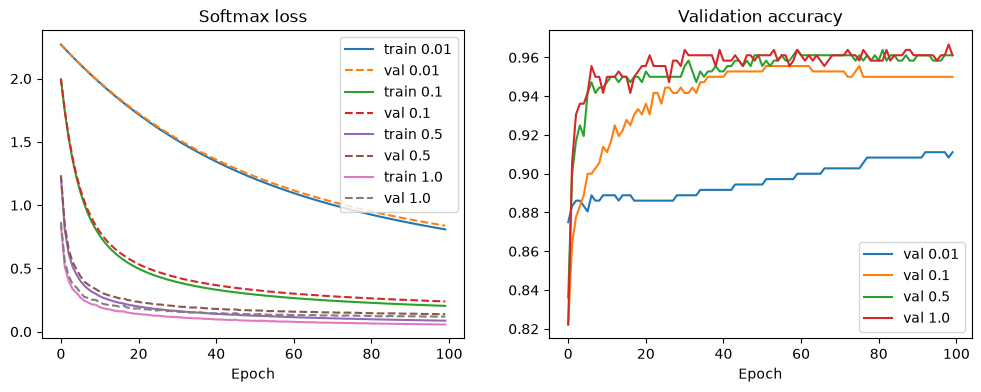

In [270]:
Xd_tr = X_train_digits
Xd_va = X_val_digits
Xd_te = X_test_digits
yd_tr = np.asarray(y_train_digits, dtype=int).ravel()
yd_va = np.asarray(y_val_digits, dtype=int).ravel()
yd_te = np.asarray(y_test_digits, dtype=int).ravel()
softmax_eta_runs={}
for eta in [.01,.1,.5,1.]:
    W, h=train_softmax_minibatch(Xd_tr,yd_tr,Xd_va,yd_va,"softmax",eta,0)
    softmax_eta_runs[eta]=(W,h)
    print("eta",eta,"final val loss/accuracy",h["val_loss"][-1],h["val_acc"][-1])
eta_star=min(softmax_eta_runs,key=lambda e:softmax_eta_runs[e][1]["val_loss"][-1])
print("Selected eta:",eta_star)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for eta,(W,h) in softmax_eta_runs.items():
    ax[0].plot(h["train_loss"],label=f"train {eta}")
    ax[0].plot(h["val_loss"],"--",label=f"val {eta}")
    ax[1].plot(h["val_acc"],label=f"val {eta}")
ax[0].set_title("Softmax loss");ax[1].set_title("Validation accuracy")
for a in ax:a.set_xlabel("Epoch");a.legend()
plt.show()

In [271]:
softmax_lam_runs={}
for lam in [0,1e-4,1e-3,1e-2,1e-1]:
    W,h=train_softmax_minibatch(Xd_tr, yd_tr, Xd_va, yd_va, "softmax", eta_star, lam)
    softmax_lam_runs[lam]=(W,h)
    print("lambda",lam,"validation accuracy",h["val_acc"][-1])
lam_star=max(softmax_lam_runs,key=lambda l:(softmax_lam_runs[l][1]["val_acc"][-1],l))
W_soft = softmax_lam_runs[lam_star][0]
print("Selected lambda", lam_star,
      "test accuracy", accuracy_score(yd_te, np.argmax(Xd_te @ W_soft, axis=1)))

lambda 0 validation accuracy 0.9611111111111111
lambda 0.0001 validation accuracy 0.9638888888888889
lambda 0.001 validation accuracy 0.9666666666666667
lambda 0.01 validation accuracy 0.9277777777777778
lambda 0.1 validation accuracy 0.6333333333333333
Selected lambda 0.001 test accuracy 0.9527777777777777


### Task 19. Off-the-shelf comparison

In [ ]:
N = len(y_train)
# =====================AI Assistanted ===============================
def fit_logreg(lam):
    Xb = X_train[:, 1:]       # drop bias; sklearn learns its own intercept
    if lam == 0:
        return LogisticRegression(C=np.inf, max_iter=10000).fit(Xb, y_train)
    return LogisticRegression(C=1/(lam*N), max_iter=10000).fit(Xb, y_train)
# ===================================================================

print(f"{'λ':>8s} {'sk_val':>8s} {'my_val':>8s} {'sk_test':>8s} {'my_test':>8s} {'agree':>7s}")
for lam in [0, 1e-4, 1e-3, 1e-2, 1e-1]:
    W, h = softmax_lam_runs[lam]

    my_val  = h["val_acc"][-1]
    my_test = np.mean(softmax(X_test @ W).argmax(1) == y_test)

    sk = fit_logreg(lam)
    sk_val  = accuracy_score(y_val,  sk.predict(X_val[:, 1:]))
    sk_test = accuracy_score(y_test, sk.predict(X_test[:, 1:]))
    agree   = np.mean(softmax(X_test @ W).argmax(1) == sk.predict(X_test[:, 1:]))

    print(f"{lam:>8.0e} {sk_val:8.4f} {my_val:8.4f} {sk_test:8.4f} {my_test:8.4f} {agree:7.4f}")

# agreement at λ*
sk_star = fit_logreg(lam_star)
agree_star = np.mean(softmax(X_test @ W_soft).argmax(1) == sk_star.predict(X_test[:, 1:]))

print(f"\nλ* = {lam_star}")
print(f"Test accuracy (ours)   : {np.mean(softmax(X_test @ W_soft).argmax(1) == y_test):.4f}")
print(f"Test accuracy (sklearn): {accuracy_score(y_test, sk_star.predict(X_test[:, 1:])):.4f}")
print(f"Test agreement at λ*   : {agree_star:.4f}   (assignment target ≥ 0.97)")

# sklearn-only C sweep (no retraining of ours)
print("\nC sweep (sklearn only):")
for C in [0.1, 1, 10, 100]:
    sk = LogisticRegression(C=C, max_iter=10000).fit(X_train[:, 1:], y_train)
    print(f"  C={C:<4g}: val={accuracy_score(y_val, sk.predict(X_val[:, 1:])):.4f} "
          f"test={accuracy_score(y_test, sk.predict(X_test[:, 1:])):.4f}")

       λ   sk_val   my_val  sk_test  my_test   agree


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 65 is different from 10)

### Task 20. Error analysis.

In [ ]:
# redefined 3shan n use our function instead of sklearn's
def confusion_matrix(y_true, y_pred , K):
    y = np.asarray (y_true, dtype=int)
    y_hat = np.asarray (y_pred, dtype=int)
    cm = np.zeros((K, K), dtype=int)

    np.add.at(cm, (y, y_hat), 1)
    return cm

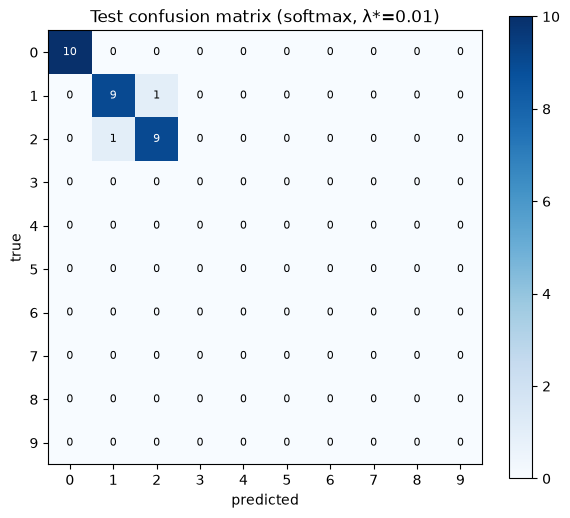

class | Precision      Recall        F1
  0   | 1.000           1.000       1.000
  1   | 0.900           0.900       0.900
  2   | 0.900           0.900       0.900
  3   | 0.000           0.000       0.000
  4   | 0.000           0.000       0.000
  5   | 0.000           0.000       0.000
  6   | 0.000           0.000       0.000
  7   | 0.000           0.000       0.000
  8   | 0.000           0.000       0.000
  9   | 0.000           0.000       0.000
macro | 0.280           0.280       0.280
Top-3 confused pairs (true → pred): [(1, 2, np.int64(1)), (2, 1, np.int64(1)), (0, 1, np.int64(0))]


ValueError: cannot reshape array of size 4 into shape (8,8)

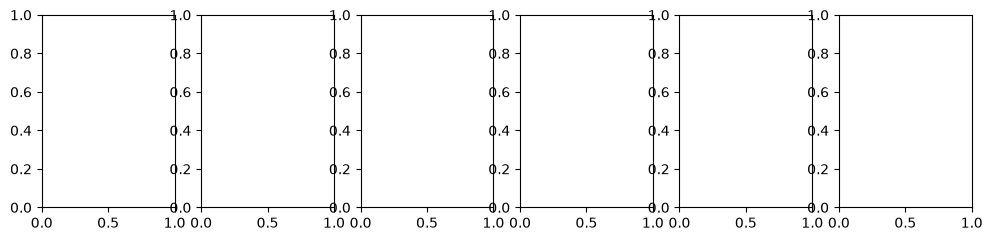

In [ ]:
K = 10
pred_te = softmax(X_test @ W_soft).argmax(1)
C_te = confusion_matrix(y_test, pred_te, K)

# confusion matrix heat map 
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(C_te, cmap="Blues")
ax.set(xlabel="predicted", ylabel="true",
       title=f"Test confusion matrix (softmax, λ*={lam_star})")
ax.set_xticks(range(K)); ax.set_yticks(range(K))
for i in range(K):
    for j in range(K):
        ax.text(j, i, C_te[i, j], ha="center", va="center",
                color="white" if C_te[i, j] > C_te.max() / 2 else "black", fontsize=8)
plt.colorbar(im); plt.show()

# per-class precision / recall / F1
m = classification_metrics(C_te)
print("class | Precision      Recall        F1")
for k in range(K):
    print(f"  {k}   | {m['precision'][k]:.3f}           {m['recall'][k]:.3f}       {m['f1_score'][k]:.3f}")
print(f"macro | {m['macros_precision']:.3f}           {m['macros_recall']:.3f}       {m['macros_f1_score']:.3f}")

# three most confused (true → pred) pairs 
pairs = [(i, j, C_te[i, j]) for i in range(K) for j in range(K) if i != j]
pairs.sort(key=lambda t: -t[2])
print("Top-3 confused pairs (true → pred):", pairs[:3])

# six misclassified test digits
wrong = np.where(pred_te != y_test)[0][:6]
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, i in zip(axes, wrong):
    ax.imshow(X_test[i, 1:].reshape(8, 8), cmap="gray_r")   
    ax.set_title(f"{y_test[i]}→{pred_te[i]}"); ax.axis("off")
plt.suptitle("Six misclassified test digits (true → predicted)")
plt.tight_layout(); 
plt.show()

# ten weight images
fig, axes = plt.subplots(1, K, figsize=(15, 2))
for k in range(K):
    axes[k].imshow(W_soft[1:, k].reshape(8, 8), cmap="RdBu_r")
    axes[k].set_title(f"class {k}"); axes[k].axis("off")
plt.suptitle("Weights W[1:,k] reshaped to 8×8")
plt.tight_layout(); plt.show()

### Task 21. Softmax with K = 2 is logistic regression.

In [ ]:
W_rand   = np.random.default_rng(42).normal(0, 0.1, (X_test_c.shape[1] + 1, 2))   # 31 × 2
scores   = add_bias(X_test_c) @ W_rand                                             # (114, 2)
p_soft   = softmax(scores)[:, 1]
p_logit  = sigmoid(scores[:, 1] - scores[:, 0])
print("max |p_softmax − p_logistic|:", np.max(np.abs(p_soft - p_logit)))

max |p_softmax − p_logistic|: 0.0


### Task 22. Seeing the boundaries.

In [ ]:
iris_split = prepared_datasets["Iris"]
X_train = add_bias(iris_split["X_train"])
X_val = add_bias(iris_split["X_val"])
X_test = add_bias(iris_split["X_test"])
y_train = iris_split["y_train"]
y_val = iris_split["y_val"]
y_test = iris_split["y_test"]

In [ ]:
# petal length (col 2) and petal width (col 3) — already standardized
X_petals = X_train[:, [2, 3]]

y_encoded = np.eye(3)[y_train]

In [ ]:
def plot_regions(X, y, predict, title, ax):
    x1 = np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 300)
    x2 = np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 300)
    xx, yy = np.meshgrid(x1, x2)
    Z = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, levels=np.arange(Z.max() + 2) - .5,  cmap = plt.cm.viridis)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", s=25, cmap = plt.cm.viridis)
    ax.set(title=title,
           xlabel="petal length (std)", ylabel="petal width (std)")

In [ ]:
def train_softmax_fullbatch(X, Y1h, lam, eta=0.5, epochs=2000):
    Xb = add_bias(X); N = len(X); K = Y1h.shape[1]
    W = np.zeros((Xb.shape[1], K))
    for _ in range(epochs):
        P = softmax(Xb @ W)
        G = Xb.T @ (P - Y1h) / N
        G[1:] += lam * W[1:]
        W -= eta * G
    return W

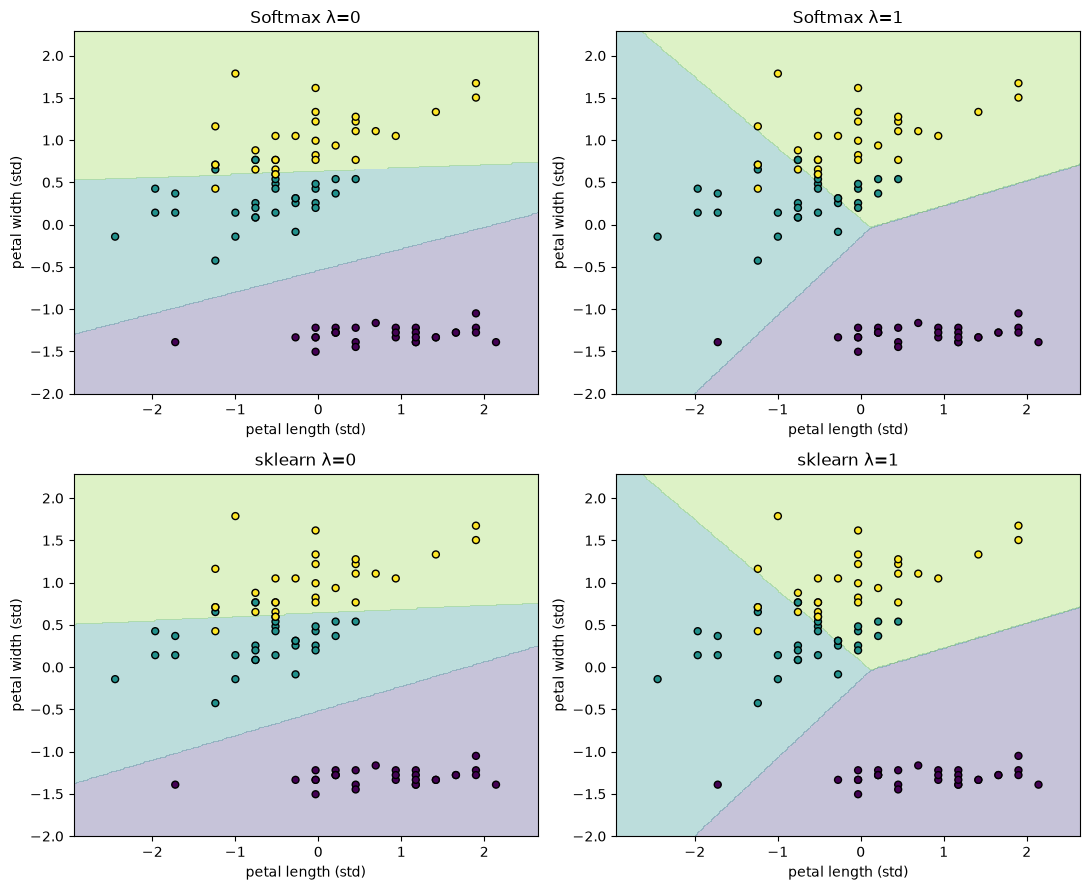

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

# Row 1 — our softmax, λ ∈ {0, 1}
for lam, ax, tag in zip([0, 1], axes[0], ["λ=0", "λ=1"]):
    W_ir = train_softmax_fullbatch(X_petals, y_encoded, lam)
    plot_regions(X_petals, y_train,
                 lambda X, W=W_ir: softmax(add_bias(X) @ W).argmax(1),
                 f"Softmax {tag}", ax)

# Row 2 — sklearn LogisticRegression, matching C = 1/(λ·N)
for lam, ax, tag in zip([0, 1], axes[1], ["λ=0", "λ=1"]):
    C = np.inf if lam == 0 else 1 / (lam * len(y_train))
    m = LogisticRegression(C=C, max_iter=10000).fit(X_petals, y_train)
    plot_regions(X_petals, y_train, m.predict, f"sklearn {tag}", ax)

plt.tight_layout(); plt.show()

# Part E:
## Task 23. Linear SVM from scratch

In [ ]:
# prepare Breast cancer data for SVM

breast_cancer_split = prepared_datasets["Breast Cancer"]

X_train_svm = breast_cancer_split["X_train"]
X_val_svm = breast_cancer_split["X_val"]
X_test_svm = breast_cancer_split["X_test"]

# prepare labels for SVM (0 → -1, 1 → +1)
y_train_svm = 2 * breast_cancer_split["y_train"] - 1
y_val_svm = 2 * breast_cancer_split["y_val"] - 1
y_test_svm = 2 * breast_cancer_split["y_test"] - 1

print("SVM training set size:", X_train_svm.shape[0])
print("SVM validation set size:", X_val_svm.shape[0])
print("SVM test set size:", X_test_svm.shape[0])

print("SVM training labels:", np.unique(y_train_svm))
print("SVM validation labels:", np.unique(y_val_svm))
print("SVM test labels:", np.unique(y_test_svm))

assert set(np.unique(y_train_svm)) == {-1, 1}
assert set(np.unique(y_val_svm)) == {-1, 1}
assert set(np.unique(y_test_svm)) == {-1, 1}

SVM training set size: 341
SVM validation set size: 114
SVM test set size: 114
SVM training labels: [-1  1]
SVM validation labels: [-1  1]
SVM test labels: [-1  1]


In [ ]:
# Linear SVM objective function and gradient

def svm_objective(theta, X, y, lambda_reg= 0.01):
    w, b = theta[:-1], theta[-1]
    margin = y * (X @ w + b)
    hinge_losses = np.maximum(0, 1 - margin)
    regularization = lambda_reg/2 * np.dot(w, w)
    return regularization + np.mean(hinge_losses)

# Linear SVM subgradient
def svm_subgradient (theta,X,y,lambda_reg= 0.01):
    w = theta[:-1]
    b = theta[-1]

    margins = y * (X @ w + b)

    # Find examples that violate the margin
    active = margins < 1

    # Calculate gradients
    grad_w = lambda_reg * w - (X[active].T @ y[active]) / len(y)
    grad_b = -np.sum(y[active]) / len(y)

    # Combine weight and bias gradients
    return np.append(grad_w, grad_b)

# Check the SVM subgradient
rng = np.random.default_rng(42)

theta_check = rng.normal(0, 0.1, size=X_train_svm.shape[1] + 1)

relative_error = grad_check(lambda theta: svm_objective(theta, X_train_svm, y_train_svm),
                            lambda theta: svm_subgradient(theta, X_train_svm, y_train_svm),
                            theta_check,epsilon=1e-6)

print("Relative error:", relative_error)

assert relative_error < 1e-5


Relative error: 1.590931850823678e-10


In [ ]:

def train_linear_svm(X_train, y_train, X_val, y_val,
                     learning_rate, iterations=3000, lam=0.01):

    theta = np.zeros(X_train.shape[1] + 1)

    objective_history = []
    val_accuracy_history = []

    for t in range(1, iterations + 1):

        gradient = svm_subgradient(theta, X_train, y_train, lam)

        if learning_rate == "decay":
            eta = 1 / np.sqrt(t)
        else:
            eta = learning_rate

        theta = theta - eta * gradient

        objective = svm_objective(theta, X_train, y_train, lam)
        objective_history.append(objective)

        val_scores = X_val @ theta[:-1] + theta[-1]
        val_predictions = np.where(val_scores >= 0, 1, -1)

        val_accuracy = np.mean(val_predictions == y_val)
        val_accuracy_history.append(val_accuracy)

    return theta, objective_history, val_accuracy_history


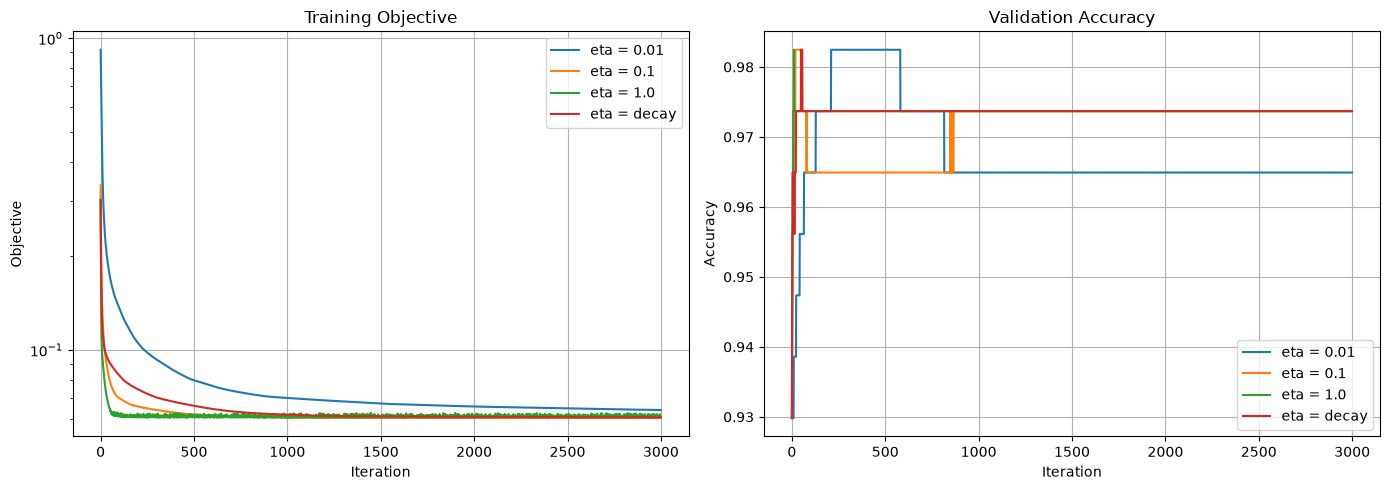

In [ ]:
import matplotlib.pyplot as plt

# Plot training objective and validation accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
svm_results = {}

learning_rates = [0.01, 0.1, 1.0, "decay"]

for lr in learning_rates:
    theta, objective_history, val_accuracy_history = train_linear_svm(
        X_train_svm,
        y_train_svm,
        X_val_svm,
        y_val_svm,
        learning_rate=lr,
        iterations=3000,
        lam=0.01
    )

    svm_results[lr] = {
        "theta": theta,
        "objective": objective_history,
        "val_accuracy": val_accuracy_history
    }

    label = f"eta = {lr}"

    # Training objective
    axes[0].plot(objective_history, label=label)

    # Validation accuracy
    axes[1].plot(val_accuracy_history, label=label)

axes[0].set_title("Training Objective")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Objective")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

A constant step size may keep oscillating around the minimum because the hinge loss is not differentiable at the margin boundary, so the subgradient can keep changing near the optimum. A decreasing step size such as 1.0/√t makes updates smaller over time, reducing these oscillations and allowing the algorithm to settle more closely. A smaller constant step size can still perform better after 3000 iterations because it makes more stable updates near the minimum. However, it may need more iterations to reach the same objective value as a larger initial step.

In [ ]:
# Train our SVM for 20,000 iterations
theta_20k, objective_history_20k, val_accuracy_history_20k = train_linear_svm(
    X_train_svm,
    y_train_svm,
    X_val_svm,
    y_val_svm,
    learning_rate="decay",
    iterations=20000,
    lam=0.01
)

print("Final objective:", objective_history_20k[-1])
print("Validation accuracy:", val_accuracy_history_20k[-1])


Final objective: 0.060449557139921756
Validation accuracy: 0.9736842105263158


In [ ]:
#Train scikit-learn SVC
from sklearn.svm import SVC

lam = 0.01
N_train = len(y_train_svm)
# c used the same regularization scaling that was already used from the objective from scratch
C_value = 1 / (lam * N_train)

svm_sklearn = SVC(kernel="linear", C=C_value)
svm_sklearn.fit(X_train_svm, y_train_svm)

print("C:", C_value)


C: 0.29325513196480935


In [ ]:
# compare the 2 models (1.Objective values, 2.Cosine similarity between weight vectors,
#3.Test prediction agreement, 4.Margin width, 5. Number of support vectors.)
# our model parameters
w_ours = theta_20k[:-1]
b_ours = theta_20k[-1]

# sklearn model parameters
w_sklearn = svm_sklearn.coef_.ravel()
b_sklearn = svm_sklearn.intercept_[0]

# Objective values on the training set
objective_ours = svm_objective(theta_20k, X_train_svm, y_train_svm, lam)

theta_sklearn = np.append(w_sklearn, b_sklearn)

objective_sklearn = svm_objective(theta_sklearn, X_train_svm, y_train_svm, lam)

# Relative objective difference
relative_objective_difference = (abs(objective_ours - objective_sklearn) / abs(objective_sklearn))

# Cosine similarity between weight vectors
cosine_similarity = np.dot(w_ours, w_sklearn) / (np.linalg.norm(w_ours) * np.linalg.norm(w_sklearn))

# Test prediction agreement
predictions_ours = np.where(X_test_svm @ w_ours + b_ours >= 0, 1, -1)

predictions_sklearn = svm_sklearn.predict(X_test_svm)

test_agreement = np.mean(predictions_ours == predictions_sklearn)

# Margin widths
margin_ours = 2 / np.linalg.norm(w_ours)
margin_sklearn = 2 / np.linalg.norm(w_sklearn)

# Number of points on or inside the margin
margins_ours = y_train_svm * (X_train_svm @ w_ours + b_ours)

support_count_ours = np.sum(margins_ours <= 1 + 1e-6)

support_count_sklearn = np.sum(svm_sklearn.n_support_)

print("Our objective:", objective_ours)
print("SVC objective:", objective_sklearn)
print("Relative objective difference:", relative_objective_difference)

print("\nCosine similarity:", cosine_similarity)
print("Test prediction agreement:", test_agreement)

print("\nOur margin width:", margin_ours)
print("SVC margin width:", margin_sklearn)

print("\nOur support vector count:", support_count_ours)
print("SVC support vector count:", support_count_sklearn)
print(
    "Support vector count difference:",
    abs(support_count_ours - support_count_sklearn)
)


Our objective: 0.060449557139921756
SVC objective: 0.06043733844117727
Relative objective difference: 0.00020217135730388745

Cosine similarity: 0.9996851265533794
Test prediction agreement: 1.0

Our margin width: 1.131752183346546
SVC margin width: 1.1291468136271114

Our support vector count: 28
SVC support vector count: 32
Support vector count difference: 4


In [ ]:
# Sweep different λ values

from sklearn.svm import LinearSVC
import pandas as pd

lambda_values = [1e-4, 1e-3, 1e-2, 1e-1, 1]

svm_comparison = []

for lam in lambda_values:

    C_value = 1 / (lam * len(y_train_svm))

    # Our SVM from scratch
    theta, _, val_acc_history = train_linear_svm(X_train_svm,y_train_svm,X_val_svm,y_val_svm,
                                                 learning_rate="decay",iterations=20000,lam=lam)

    w = theta[:-1]
    b = theta[-1]

    our_val_predictions = np.where(X_val_svm @ w + b >= 0, 1, -1)
    our_val_accuracy = np.mean(our_val_predictions == y_val_svm)

    our_margin = 2 / np.linalg.norm(w)

    our_train_margins = y_train_svm * (X_train_svm @ w + b)

    our_sv_count = np.sum(our_train_margins <= 1 + 1e-6)

    # SVC with linear kernel
    svc = SVC(kernel="linear", C=C_value)
    svc.fit(X_train_svm, y_train_svm)

    svc_val_accuracy = svc.score(X_val_svm, y_val_svm)

    svc_margin = 2 / np.linalg.norm(svc.coef_.ravel())
    svc_sv_count = np.sum(svc.n_support_)

    # LinearSVC with hinge loss
    linear_svc = LinearSVC(C=C_value,loss="hinge",max_iter=100000,random_state=42)
    linear_svc.fit(X_train_svm, y_train_svm)

    linear_svc_val_accuracy = linear_svc.score(X_val_svm, y_val_svm)

    linear_svc_margin = (2 / np.linalg.norm(linear_svc.coef_.ravel()))

    linear_svc_margins = y_train_svm * (X_train_svm @ linear_svc.coef_.ravel() + linear_svc.intercept_[0])

    linear_svc_sv_count = np.sum(linear_svc_margins <= 1 + 1e-6)

    # Save results
    svm_comparison.append({
        "Lambda": lam,
        "C": C_value,

        "Our Val Accuracy": our_val_accuracy,
        "Our Margin Width": our_margin,
        "Our SV Count": our_sv_count,

        "SVC Val Accuracy": svc_val_accuracy,
        "SVC Margin Width": svc_margin,
        "SVC SV Count": svc_sv_count,

        "LinearSVC Val Accuracy": linear_svc_val_accuracy,
        "LinearSVC Margin Width": linear_svc_margin,
        "LinearSVC SV Count": linear_svc_sv_count
    })

svm_comparison_df = pd.DataFrame(svm_comparison)

svm_comparison_df


,Lambda,C,Our Val Accuracy,Our Margin Width,Our SV Count,SVC Val Accuracy,SVC Margin Width,SVC SV Count,LinearSVC Val Accuracy,LinearSVC Margin Width,LinearSVC SV Count
0,0.0001,29.325513,0.964912,0.592339,15,0.947368,0.146007,22,0.947368,0.145978,10
1,0.0010,2.932551,0.973684,0.653872,17,0.964912,0.462039,28,0.964912,0.463402,21
2,0.0100,0.293255,0.973684,1.131752,28,0.973684,1.129147,32,0.973684,1.123488,28
3,0.1000,0.029326,0.982456,2.168837,56,0.982456,2.168839,61,0.973684,2.164157,59
4,1.0000,0.002933,0.964912,4.711695,122,0.964912,4.711890,125,0.964912,4.457991,135


In [ ]:
# Multiclass hinge vs. softmax
def ww_loss(W, X, y, lam=0, delta=1):
    # Calculate scores for all samples and classes
    scores = X @ W

    # Get the score of the correct class for each sample
    correct_scores = scores[np.arange(len(y)), y][:, None]

    # Calculate the margins
    margins = np.maximum(0, scores - correct_scores + delta)

    # The correct class should not contribute to the loss
    margins[np.arange(len(y)), y] = 0

    # Average data loss
    data_loss = np.mean(np.sum(margins, axis=1))

    # Regularization (excluding the bias row)
    reg_loss = (lam / 2) * np.sum(W[1:] ** 2)

    return data_loss + reg_loss


# Check the loss when all weights are zero
W_zero = np.zeros((X_train_digits.shape[1], 10))

zero_loss = ww_loss(W_zero,X_train_digits,y_train_digits)

print("Loss at W = 0:", zero_loss)
print("Expected loss:", 9)



Loss at W = 0: 9.0
Expected loss: 9


In [ ]:
def ww_grad(W, X, y, lam=0, delta=1):
    # Calculate scores
    scores = X @ W

    # Get the correct class scores
    correct_scores = scores[np.arange(len(y)), y][:, None]

    # Calculate margins
    margins = scores - correct_scores + delta

    # Create matrix B
    B = (margins > 0).astype(float)

    # The correct class does not count as an incorrect class
    B[np.arange(len(y)), y] = 0

    # Set the correct class entries to the negative number of violations
    B[np.arange(len(y)), y] = -np.sum(B, axis=1)

    # Calculate the gradient
    G = X.T @ B / len(y)

    # Add regularization gradient (excluding bias)
    G[1:] += lam * W[1:]

    return G


In [ ]:
def ww_gradient_check(W, X, y, lam=0, num_checks=100, h=1e-5):
    # Calculate analytical gradient
    analytical_grad = ww_grad(W, X, y, lam)

    # Initialize numerical gradient
    numerical_grad = np.zeros_like(W)

    # Choose 100 random weight positions
    rng = np.random.default_rng(42)

    indices = [(rng.integers(W.shape[0]), rng.integers(W.shape[1])) for _ in range(num_checks)]

    # Calculate numerical gradient for selected positions
    for i, j in indices:
        W_plus = W.copy()
        W_minus = W.copy()

        W_plus[i, j] += h
        W_minus[i, j] -= h

        loss_plus = ww_loss(W_plus, X, y, lam)
        loss_minus = ww_loss(W_minus, X, y, lam)

        numerical_grad[i, j] = (loss_plus - loss_minus) / (2 * h)

    # Compare analytical and numerical gradients
    analytical_values = np.array([analytical_grad[i, j] for i, j in indices])
    numerical_values = np.array([numerical_grad[i, j] for i, j in indices])

    numerator = np.linalg.norm(analytical_values - numerical_values)

    denominator = (np.linalg.norm(analytical_values) + np.linalg.norm(numerical_values) + 1e-12)

    relative_error = numerator / denominator

    return relative_error


# Use random weights for the gradient check
rng = np.random.default_rng(42)

W_check = rng.normal(0, 0.01, size=(X_train_digits.shape[1], 10))

gradient_error = ww_gradient_check(W_check, X_train_digits,y_train_digits, lam=0.001)

print("Weston-Watkins gradient relative error:", gradient_error)


Weston-Watkins gradient relative error: 1.9396039081671657e-10


In [ ]:
print(X_train_digits.shape, y_train_digits.shape)
print(X_val_digits.shape, y_val_digits.shape)
print(X_test_digits.shape, y_test_digits.shape)

(1077, 65) (1077,)
(360, 65) (360,)
(360, 65) (360,)


In [ ]:
ww_eta_runs = {}

for eta in [0.01, 0.1, 0.5]:
    W, h = train_softmax_minibatch(
        X_train_digits, y_train_digits,
        X_val_digits, y_val_digits,
        "ww", eta, 0
    )

    ww_eta_runs[eta] = (W, h)

    print(
        "eta:", eta,
        "final val loss:", h["val_loss"][-1],
        "final val accuracy:", h["val_acc"][-1]
    )

eta_star_ww = min(
    ww_eta_runs,
    key=lambda e: ww_eta_runs[e][1]["val_loss"][-1]
)

print("Selected SVM eta:", eta_star_ww)


eta: 0.01 final val loss: 0.31263002209293533 final val accuracy: 0.95
eta: 0.1 final val loss: 0.170185324231034 final val accuracy: 0.9611111111111111
eta: 0.5 final val loss: 0.14061465313349628 final val accuracy: 0.9611111111111111
Selected SVM eta: 0.5


In [ ]:
ww_lam_runs = {}

for lam in [0, 1e-4, 1e-3, 1e-2]:
    W, h = train_softmax_minibatch(
        X_train_digits, y_train_digits,
        X_val_digits, y_val_digits,
        "ww", eta_star_ww, lam
    )

    ww_lam_runs[lam] = (W, h)

    print("lambda:", lam, "validation accuracy:", h["val_acc"][-1])

lam_star_ww = max(
    ww_lam_runs,
    key=lambda l: (ww_lam_runs[l][1]["val_acc"][-1], l)
)

W_ww = ww_lam_runs[lam_star_ww][0]

val_acc_ww = ww_lam_runs[lam_star_ww][1]["val_acc"][-1]

test_acc_ww = accuracy_score(
    y_test_digits,
    np.argmax(X_test_digits @ W_ww, axis=1)
)

print("Selected SVM lambda:", lam_star_ww)
print("SVM validation accuracy:", val_acc_ww)
print("SVM test accuracy:", test_acc_ww)


lambda: 0 validation accuracy: 0.9611111111111111
lambda: 0.0001 validation accuracy: 0.9638888888888889
lambda: 0.001 validation accuracy: 0.9694444444444444
lambda: 0.01 validation accuracy: 0.9444444444444444
Selected SVM lambda: 0.001
SVM validation accuracy: 0.9694444444444444
SVM test accuracy: 0.95


In [ ]:
digits_softmax_eta_runs = {}

for eta in [0.01, 0.1, 0.5, 1.0]:

    W, h = train_softmax_minibatch(
        X_train_digits, y_train_digits,
        X_val_digits, y_val_digits,
        "softmax", eta, 0
    )

    digits_softmax_eta_runs[eta] = (W, h)

    print(
        "eta:", eta,
        "final val loss:", h["val_loss"][-1],
        "final val accuracy:", h["val_acc"][-1]
    )

digits_softmax_eta_star = min(
    digits_softmax_eta_runs,
    key=lambda e: digits_softmax_eta_runs[e][1]["val_loss"][-1]
)

print("Selected Softmax eta:", digits_softmax_eta_star)


eta: 0.01 final val loss: 0.8373881159118635 final val accuracy: 0.9111111111111111
eta: 0.1 final val loss: 0.23895135088073974 final val accuracy: 0.95
eta: 0.5 final val loss: 0.13832893605587426 final val accuracy: 0.9611111111111111
eta: 1.0 final val loss: 0.11932709452886109 final val accuracy: 0.9611111111111111
Selected Softmax eta: 1.0


In [ ]:
digits_softmax_lam_runs = {}

for lam in [0, 1e-4, 1e-3, 1e-2, 1e-1]:

    W, h = train_softmax_minibatch(
        X_train_digits, y_train_digits,
        X_val_digits, y_val_digits,
        "softmax", digits_softmax_eta_star, lam
    )

    digits_softmax_lam_runs[lam] = (W, h)

    print(
        "lambda:", lam,
        "validation accuracy:", h["val_acc"][-1]
    )

digits_softmax_lam_star = max(
    digits_softmax_lam_runs,
    key=lambda l: (
        digits_softmax_lam_runs[l][1]["val_acc"][-1], l
    )
)

W_soft_digits = digits_softmax_lam_runs[digits_softmax_lam_star][0]

val_acc_soft = accuracy_score(
    y_val_digits,
    np.argmax(X_val_digits @ W_soft_digits, axis=1)
)

test_acc_soft = accuracy_score(
    y_test_digits,
    np.argmax(X_test_digits @ W_soft_digits, axis=1)
)

print("Selected Softmax lambda:", digits_softmax_lam_star)
print("Softmax validation accuracy:", val_acc_soft)
print("Softmax test accuracy:", test_acc_soft)

lambda: 0 validation accuracy: 0.9611111111111111
lambda: 0.0001 validation accuracy: 0.9638888888888889
lambda: 0.001 validation accuracy: 0.9666666666666667
lambda: 0.01 validation accuracy: 0.9277777777777778
lambda: 0.1 validation accuracy: 0.6333333333333333
Selected Softmax lambda: 0.001
Softmax validation accuracy: 0.9666666666666667
Softmax test accuracy: 0.9527777777777777


In [ ]:
scores_list = [
    np.array([10, -5, -5]),
    np.array([100, -50, -50]),
    np.array([3.2, 5.1, -1.7])
]

for i, scores in enumerate(scores_list):
    svm_loss_value = sum(
        max(0, scores[j] - scores[0] + 1)
        for j in range(1, 3)
    )

    shifted = scores - np.max(scores)
    softmax_probs = np.exp(shifted) / np.sum(np.exp(shifted))
    softmax_loss_value = -np.log(softmax_probs[0])

    print(
        f"Example {i+1}: "
        f"SVM loss = {svm_loss_value:.6f}, "
        f"Softmax loss = {softmax_loss_value:.6f}"
    )

Example 1: SVM loss = 0.000000, Softmax loss = 0.000001
Example 2: SVM loss = 0.000000, Softmax loss = -0.000000
Example 3: SVM loss = 2.900000, Softmax loss = 2.040355


The SVM loss stops caring about a sample once the correct class score exceeds every incorrect class score by at least the required margin. Softmax continues to push the correct class probability closer to 1, even after the classification is correct. Therefore, SVM focuses on satisfying the margins, while Softmax encourages more confident predictions. However, Softmax probabilities are not automatically calibrated probabilities.

## Task 26:

In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd

# Part 1: Compare different kernels with C = 1

kernels = {
    "Linear": SVC(kernel="linear", C=1),
    "Polynomial": SVC(kernel="poly", degree=3, coef0=1, gamma="scale", C=1),
    "RBF": SVC(kernel="rbf", gamma="scale", C=1)
}

kernel_results = []

for name, model in kernels.items():
    model.fit(X_train_svm, y_train_svm)

    train_acc = accuracy_score(y_train_svm, model.predict(X_train_svm))
    val_acc = accuracy_score(y_val_svm, model.predict(X_val_svm))
    test_acc = accuracy_score(y_test_svm, model.predict(X_test_svm))

    n_support = model.n_support_.sum()

    kernel_results.append({
        "Kernel": name,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Test Accuracy": test_acc,
        "Number of Support Vectors": n_support
    })

kernel_results_df = pd.DataFrame(kernel_results)
display(kernel_results_df)

,Kernel,Train Accuracy,Validation Accuracy,Test Accuracy,Number of Support Vectors
0,Linear,0.988270,0.964912,0.929825,30
1,Polynomial,0.991202,0.982456,0.973684,52
2,RBF,0.982405,0.982456,0.973684,88


In [ ]:
# Part 2: Effect of C
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

C_results = []

for C in C_values:
    model = SVC(kernel="linear", C=C)
    model.fit(X_train_svm, y_train_svm)

    train_acc = accuracy_score(y_train_svm, model.predict(X_train_svm))
    val_acc = accuracy_score(y_val_svm, model.predict(X_val_svm))

    n_support = model.n_support_.sum()

    # Calculate margin width = 2 / ||w||
    w_norm = np.linalg.norm(model.coef_[0])
    margin_width = 2 / w_norm

    C_results.append({
        "C": C,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Number of Support Vectors": n_support,
        "Margin Width": margin_width
    })

C_results_df = pd.DataFrame(C_results)
display(C_results_df)

,C,Train Accuracy,Validation Accuracy,Number of Support Vectors,Margin Width
0,0.001,0.932551,0.956140,175,6.761937
1,0.010,0.973607,0.973684,83,3.168999
2,0.100,0.979472,0.964912,43,1.566853
3,1.000,0.988270,0.964912,30,0.672679
4,10.000,0.997067,0.938596,23,0.247084
5,100.000,1.000000,0.947368,22,0.146007


As C increases, training accuracy generally increases, while the number of support vectors and margin width decrease. A small C allows more training errors and produces a wider margin, while a large C penalizes classification errors more strongly and produces a narrower margin. However, increasing C does not always improve validation accuracy. In our case, C = 0.01 achieved the highest validation accuracy of 97.37%, while C = 100 achieved 100% training accuracy but lower validation accuracy. This shows that choosing C based on validation performance is important to avoid overfitting.

## Task 27:

In [ ]:

#part 1: Prepare the two features

#select only mean radius and mean texture
#these are the first two features in the Breast Cancer dataset

X_train_2d = X_train_svm[:, :2]
X_val_2d = X_val_svm[:, :2]

#gamma values to test
gamma_values = [0.01, 0.1, 1, 10, 100]

In [ ]:
#Part 2: Train and compare Gamma values

gamma_results = []

gamma_models = {}

for gamma in gamma_values:
    model = SVC(kernel="rbf", C=1, gamma=gamma)
    model.fit(X_train_2d, y_train_svm)

    train_acc = accuracy_score(
        y_train_svm, model.predict(X_train_2d)
    )

    val_acc = accuracy_score(
        y_val_svm, model.predict(X_val_2d)
    )

    n_support = model.n_support_.sum()

    gamma_results.append({
        "Gamma": gamma,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Number of Support Vectors": n_support
    })

    gamma_models[gamma] = model

gamma_results_df = pd.DataFrame(gamma_results)
display(gamma_results_df)


,Gamma,Train Accuracy,Validation Accuracy,Number of Support Vectors
0,0.01,0.882698,0.868421,166
1,0.10,0.900293,0.894737,109
2,1.00,0.912023,0.894737,108
3,10.00,0.929619,0.877193,201
4,100.00,0.982405,0.736842,311


As gamma increases, the RBF SVM can learn more complex decision boundaries. In our case, gamma = 0.01 produced relatively low training and validation accuracy, behaving almost like a linear model. The highest validation accuracy was 89.47%, achieved with gamma = 0.1 and gamma = 1.However, at gamma = 100, training accuracy increased to 98.24% while validation accuracy dropped to 73.68%, indicating overfitting.The number of support vectors also increased to 311, showing that the model became more complex.

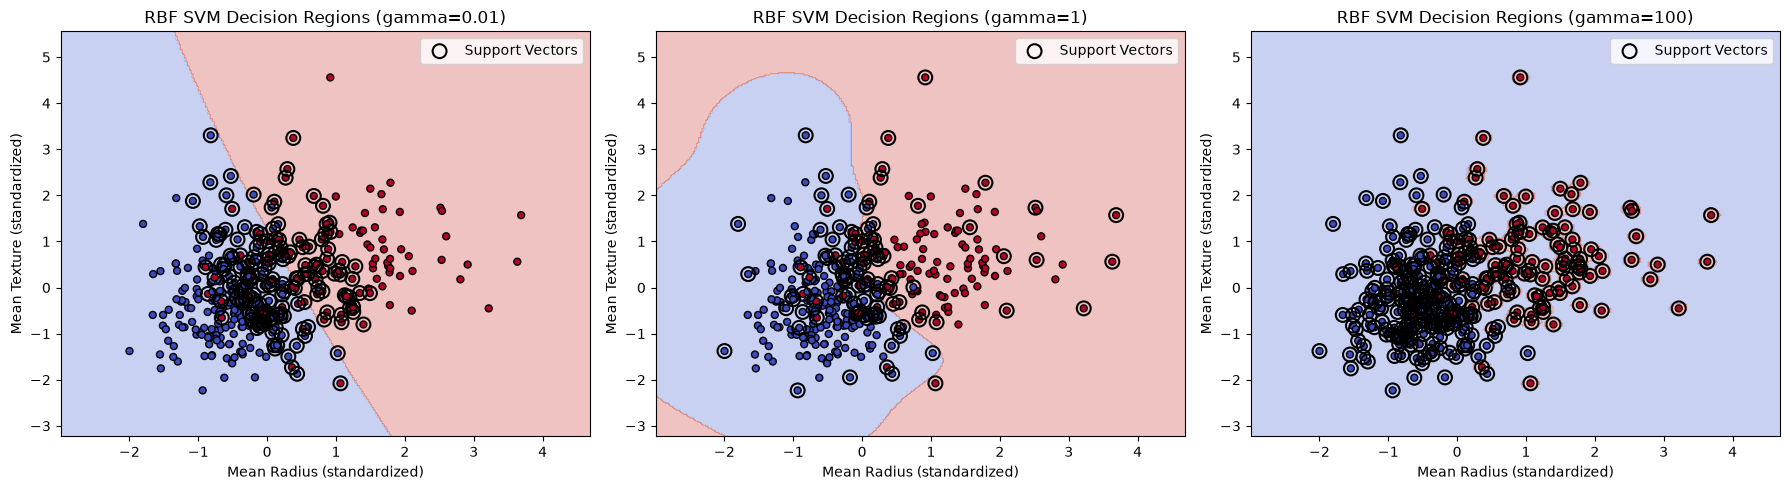

In [ ]:
# Desicion regions 

import matplotlib.pyplot as plt

selected_gammas = [0.01, 1, 100]

# Create a grid covering the feature space
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, gamma in zip(axes, selected_gammas):
    model = gamma_models[gamma]

    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

    # plot training points
    ax.scatter(
        X_train_2d[:, 0],
        X_train_2d[:, 1],
        c=y_train_svm,
        cmap="coolwarm",
        edgecolors="k",
        s=25
    )

    # circle the support vectors
    support_vectors = model.support_vectors_

    ax.scatter(
        support_vectors[:, 0],
        support_vectors[:, 1],
        s=100,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        label="Support Vectors"
    )

    ax.set_title(f"RBF SVM Decision Regions (gamma={gamma})")
    ax.set_xlabel("Mean Radius (standardized)")
    ax.set_ylabel("Mean Texture (standardized)")
    ax.legend()

plt.tight_layout()
plt.show()

## Task 28: 

In [ ]:
X_train_digits_svm = X_train_digits[:, 1:]
X_test_digits_svm = X_test_digits[:, 1:]

In [ ]:
print("Train shape:", X_train_digits_svm.shape)
print("Test shape:", X_test_digits_svm.shape)

Train shape: (1077, 64)
Test shape: (360, 64)


In [ ]:
# GridSearchCV

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# values we want to test
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1]
}

# 5-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# create RBF SVM
svm_model = SVC(kernel="rbf")

# Try all parameter combinations
grid_search = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="accuracy"
)

# Train and compare the combinations
grid_search.fit(X_train_digits_svm, y_train_digits)

# Show the best combination
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

# Test the selected model only once
best_svm = grid_search.best_estimator_
y_test_pred = best_svm.predict(X_test_digits_svm)

test_accuracy = accuracy_score(y_test_digits, y_test_pred)
print("Test Accuracy:", test_accuracy)

Best Parameters: {'C': 10, 'gamma': 0.1}
Best CV Accuracy: 0.9851464254952627
Test Accuracy: 0.9916666666666667


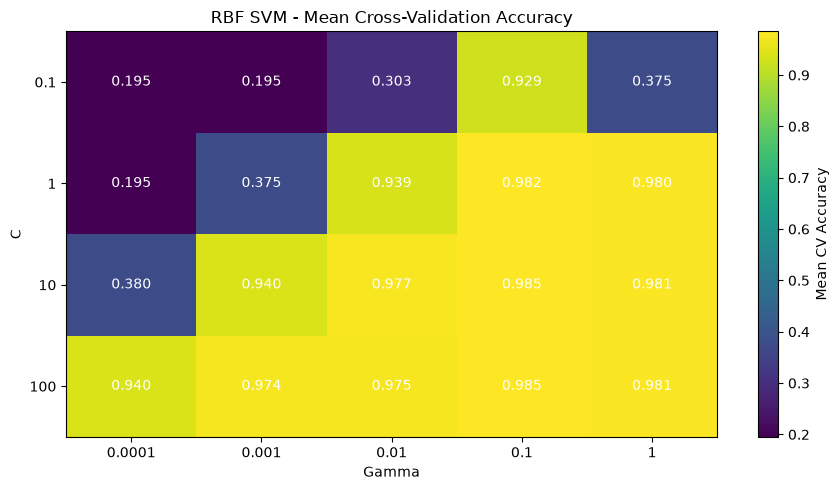

In [ ]:
# Heatmap

import matplotlib.pyplot as plt
import numpy as np

# Get the mean CV accuracy for all combinations
cv_scores = grid_search.cv_results_["mean_test_score"]

# Arrange the scores in a matrix
heatmap_data = cv_scores.reshape(4, 5)

# Plot the heatmap
plt.figure(figsize=(9, 5))

plt.imshow(heatmap_data, cmap="viridis", aspect="auto")

plt.xticks(
    range(5),
    param_grid["gamma"]
)

plt.yticks(
    range(4),
    param_grid["C"]
)

plt.xlabel("Gamma")
plt.ylabel("C")
plt.title("RBF SVM - Mean Cross-Validation Accuracy")

plt.colorbar(label="Mean CV Accuracy")

# Show the accuracy values inside each cell
for i in range(4):
    for j in range(5):
        plt.text(
            j, i,
            f"{heatmap_data[i, j]:.3f}",
            ha="center",
            va="center",
            color="white"
        )

plt.tight_layout()
plt.show()

The best results appear in a diagonal shape because both C and gamma affect the decision boundary. A large gamma makes the boundary more complex, while a small gamma makes it smoother. C also affects how much the model tries to avoid classification errors, so changing C and gamma together can give similar accuracy.

## Task 30: One Framework, Four Losses

| Model | Per-sample loss ℓ(s, y) | Gradient ∂ℓ/∂s | Output meaning |
|---|---|---|---|
| Linear regression | ½(s − y)² | s − y | Continuous numerical value |
| Logistic regression | −y log(p) − (1−y) log(1−p) | p − y | Probability of the positive class |
| Softmax classifier | −log(Py) | p − True Class Vector | Probabilities for all classes |
| Binary / multiclass SVM | Hinge loss | Piecewise gradient | Decision scores (margins) |

Where:

Logistic regression: p = σ(s)

Softmax: p_k = exp(Sk) / Σ_j exp(Sj)

Binary SVM: ℓ = max(0, 1 − ys)

Multiclass SVM (Weston–Watkins): ℓ = Σ_(j≠y) max(0, Sj − Sy + 1)

Answer:
The gradients of linear regression, logistic regression, and softmax have the form prediction − target. SVM is different because it uses hinge loss. It only updates samples that violate the required margin. If the margin is satisfied, the gradient becomes zero.

## Task 31: Conclusions

### (a) When to Choose Each Model

- **Ridge Regression:** Suitable for predicting continuous values. L2 regularization helps reduce overfitting by keeping weights small.
- **Logistic Regression:** Suitable for binary classification when we need positive-class probabilities.
- **Softmax Classifier:** Suitable for multiclass classification. It achieved 95.28% test accuracy on the Digits dataset.
- **Linear SVM:** Suitable for data that can be separated using a linear boundary. It aims to maximize the margin.
- **Kernel SVM:** Suitable for nonlinear data. In our Breast Cancer experiment, Polynomial and RBF kernels achieved 97.37% test accuracy, compared to 92.98% for the Linear kernel.

### (b) Probabilities vs. Margins

- **Logistic Regression:** Outputs positive-class probabilities using the sigmoid function.
- **Softmax:** Outputs probabilities for all classes.
- **SVM:** Outputs decision scores called margins, not probabilities. Probability estimates require an additional calibration method.
- **Ridge Regression:** Outputs continuous numerical predictions.

Logistic Regression and Softmax probabilities are not necessarily well-calibrated.

### (c) Effect of a Badly Misclassified Outlier

- **Squared Loss:** Penalizes large errors quadratically, so outliers can have a very large effect on the total loss.
- **Logistic Loss:** Strongly penalizes confidently wrong predictions, with the loss growing approximately linearly for very large errors.
- **Hinge Loss:** Penalizes misclassified samples and samples within the required margin. Correctly classified samples outside the margin have zero loss.

### (d) Training and Prediction Cost

- **Linear Models:** Training generally takes \(O(E \times N \times d)\), where E is the number of epochs, N the number of samples, and d the number of features. Prediction takes \(O(d)\) per sample.
- **Kernel SVM:** Training can range from \(O(N^2)\) to \(O(N^3)\). Prediction takes approximately \(O(SV \times d)\), where SV is the number of support vectors.

Linear models are generally more scalable for large datasets.

### (e) What Surprised Me Most

I was surprised by how much kernel choice affected SVM performance. Polynomial and RBF kernels achieved 97.37% test accuracy, compared to 92.98% for the Linear kernel. Also, a very high gamma caused overfitting, increasing training accuracy while reducing performance on unseen data.
